In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path

In [47]:
df = yf.download("NVDA", start="2000-01-01", end='2026-11-12')
df.columns = df.columns.droplevel(1)


[*********************100%***********************]  1 of 1 completed


In [48]:
print(f"SHAPE: {df.shape}")

SHAPE: (6756, 5)


In [49]:
df.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2000-01-03,0.089206,0.090755,0.084085,0.090041,300912000
2000-01-04,0.086825,0.087897,0.082418,0.087658,300480000
2000-01-05,0.083966,0.085753,0.082775,0.084324,188352000
2000-01-06,0.078487,0.083966,0.075272,0.083966,120480000
2000-01-07,0.079798,0.080631,0.076939,0.078130,71184000


- Open: Giá mở cửa
- High: Giá cao nhất trong phiên giao dịch
- Low: Giá thấp nhất trong phiên giao dịch
- Close: Giá đóng cửa
- Adj Close: Giá đóng cửa hiệu chỉnh (cột qun trong nhất, phản ánh các hành động của công ty)
- Volume: Tổng khối lượng giao dịch

In [50]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6756 entries, 2000-01-03 to 2026-11-11
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   6756 non-null   float64
 1   High    6756 non-null   float64
 2   Low     6756 non-null   float64
 3   Open    6756 non-null   float64
 4   Volume  6756 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 316.7 KB


In [51]:
def time_plot(df):
    # Khởi tạo Figure
    fig = plt.figure(figsize=(14, 10))
    fig.suptitle("Time Plot", fontsize=16)

    gs = fig.add_gridspec(3, 2)

    dates = df.index

    ax_vol = fig.add_subplot(gs[0, :])
    ax_vol.plot(dates, df['Volume'])
    ax_vol.set_title("Volume")

    ax_open = fig.add_subplot(gs[1, 0])
    ax_open.plot(dates, df['Open'])
    ax_open.set_title("Open")

    ax_close = fig.add_subplot(gs[1, 1])
    ax_close.plot(dates, df['Close'])
    ax_close.set_title("Close")

    ax_high = fig.add_subplot(gs[2, 0])
    ax_high.plot(dates, df['High'])
    ax_high.set_title("High")

    ax_low = fig.add_subplot(gs[2, 1])
    ax_low.plot(dates, df['Low'])
    ax_low.set_title("Low")

    plt.tight_layout(pad=3.0, h_pad=2.5, w_pad=2.0)
    plt.show()

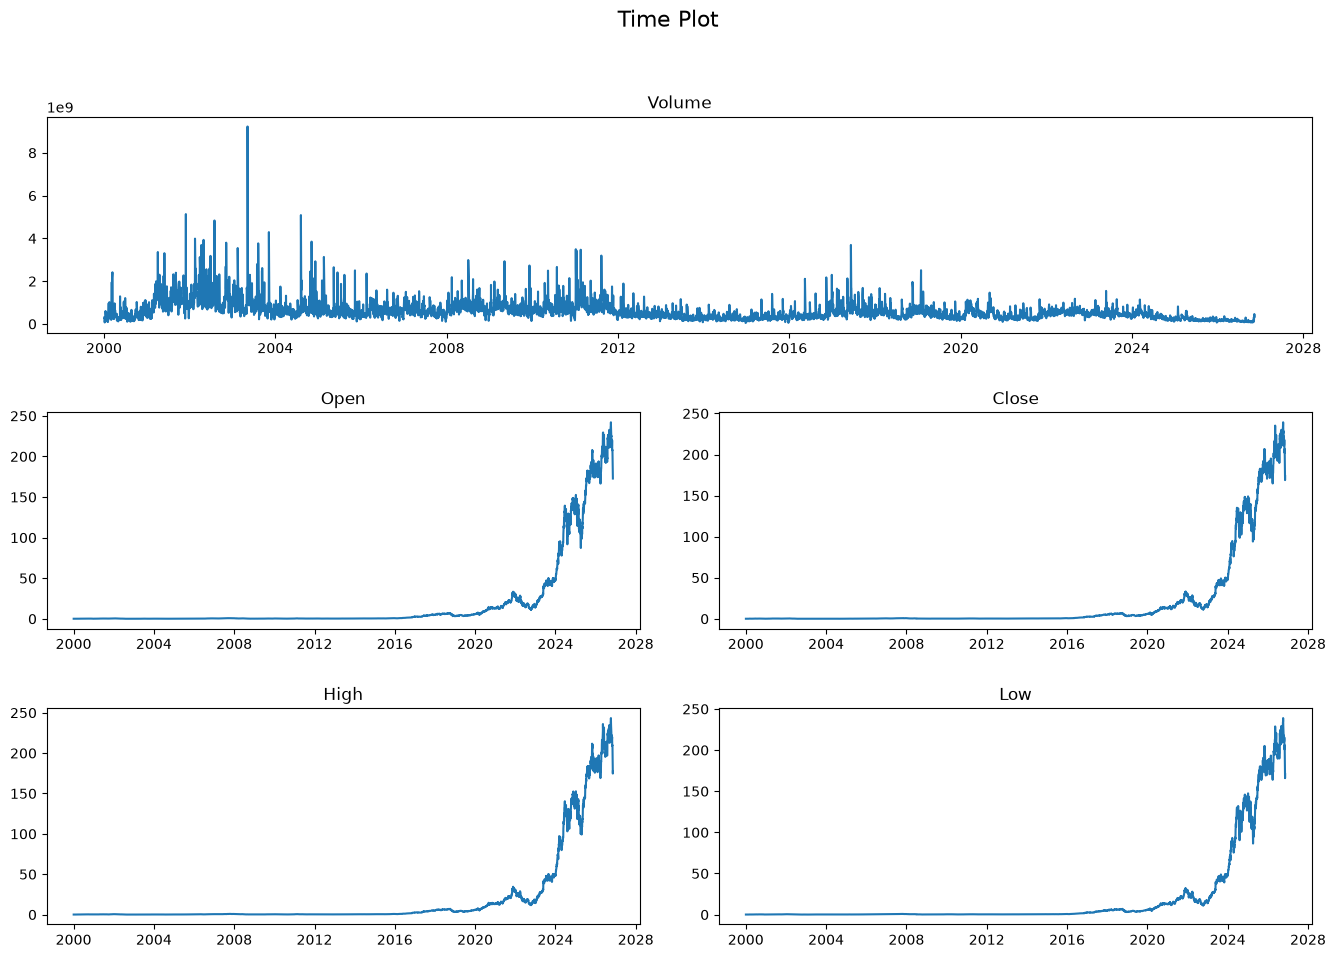

In [52]:
time_plot(df)

### Nhận xét về xu hướng (Trend)

- Giá cổ phiếu có xu hướng tăng mạnh trong dài hạn.
- Điều này cho thấy giá cổ phiếu nhìn chung tăng theo thời gian.

### Nhận xét về tính mùa vụ (Seasonality)

- Không có dấu hiệu rõ ràng về tính mùa vụ trong dài hạn.
- Biến động giá chủ yếu phụ thuộc vào điều kiện thị trường thay vì tuân theo các chu kỳ mùa vụ cố định.

### Nhận xét về nhiễu (Noise)

- Nhiễu thể hiện rõ qua những biến động giá hằng ngày, với đường biểu diễn giá xuất hiện nhiều dao động liên tục.
- Biểu đồ khối lượng giao dịch (Volume) chịu ảnh hưởng chủ yếu bởi nhiễu, thể hiện qua các đợt tăng đột biến ngẫu nhiên và khó dự đoán, đặc biệt đối với cổ phiếu NVDA.
- Những biến động về khối lượng giao dịch này không cho thấy xu hướng rõ ràng.

---
## Thực hiện trên các thao tác trên cột Close

In [53]:
# Thực hiện các thao tác trên 1 cột Close này.
df_close_series = pd.Series(df['Close'])

In [54]:
def calc_max_lag(series: pd.Series) -> int:
    n = series.count()
    max_lag = int(min(10 * np.log10(n), n / 5)) if n > 0 else 0

    return max_lag

### ACF (Autocorrelation Function)

- Đo lường mức độ tương quan tuyến tính giữa một chuỗi thời gian ($Y_t$) và chính nó tại thời điểm trễ \(k\) bước trong quá khứ ($(Y_{t-k}$).
- ACF cho biết mức độ tương quan giữa giá trị hiện tại và các giá trị trong quá khứ tại từng độ trễ (*lag*).

**Ý nghĩa:** Cho biết giá trị hiện tại có mối tương quan mạnh hay yếu với các giá trị trong quá khứ.

# Công thức tính Hàm tự tương quan (ACF - Autocorrelation Function)

Hàm tự tương quan (ACF) đo lường mức độ tương quan tuyến tính giữa chuỗi thời gian $x_t$ và phiên bản trễ của chính nó tại độ trễ (lag) $k$: $x_{t-k}$.

---

## 1. Công thức tính trên dữ liệu mẫu (Sample ACF)

Cho một chuỗi thời gian rời rạc gồm $N$ quan sát: $x_1, x_2, \dots, x_N$.

### Bước 1: Tính giá trị trung bình mẫu ($\bar{x}$)
$$\bar{x} = \frac{1}{N} \sum_{t=1}^{N} x_t$$

### Bước 2: Tính tự hiệp phương sai mẫu tại độ trễ $k$ ($c_k$)
$$c_k = \frac{1}{N} \sum_{t=k+1}^{N} (x_t - \bar{x})(x_{t-k} - \bar{x})$$

*(Lưu ý: Mẫu số chuẩn trong phân tích chuỗi thời gian dùng $N$ thay vì $N - k$ để đảm bảo ma trận tự hiệp phương sai luôn xác định dương).*

### Bước 3: Tính phương sai mẫu tại độ trễ $0$ ($c_0$)
$$c_0 = \frac{1}{N} \sum_{t=1}^{N} (x_t - \bar{x})^2$$

### Bước 4: Tính hệ số tự tương quan mẫu tại độ trễ $k$ ($r_k$ hoặc $\hat{\rho}_k$)
$$r_k = \frac{c_k}{c_0} = \frac{\sum_{t=k+1}^{N} (x_t - \bar{x})(x_{t-k} - \bar{x})}{\sum_{t=1}^{N} (x_t - \bar{x})^2}$$

---

## 2. Công thức lý thuyết (Population ACF)

Đối với một quá trình ngẫu nhiên dừng yếu (weakly stationary) $X_t$ có kỳ vọng $\mu = \mathbb{E}[X_t]$:

* **Hàm tự hiệp phương sai (Autocovariance):**
  $$\gamma(k) = \text{Cov}(X_t, X_{t-k}) = \mathbb{E}[(X_t - \mu)(X_{t-k} - \mu)]$$

* **Hàm tự tương quan (Autocorrelation):**
  $$\rho(k) = \frac{\gamma(k)}{\gamma(0)} = \frac{\text{Cov}(X_t, X_{t-k})}{\text{Var}(X_t)}$$

---

## 3. Khoảng tin cậy 95% (Kiểm định nhiễu trắng - White Noise)

Để kiểm tra xem hệ số $r_k$ có ý nghĩa thống kê hay không (so với giả thuyết $H_0$: chuỗi là nhiễu trắng độc lập phân phối chuẩn):

$$\text{Ngưỡng tin cậy 95\%} = \pm \frac{1.96}{\sqrt{N}}$$

* Nếu $|r_k| > \frac{1.96}{\sqrt{N}}$: Tự tương quan tại độ trễ $k$ có ý nghĩa thống kê (vượt ra ngoài dải xanh trên biểu đồ ACF).
* **Tính chất cơ bản:** $\rho(0) = 1$, $-1 \le \rho(k) \le 1$, và tính đối xứng $\rho(-k) = \rho(k)$.

In [55]:
# Cov/Var
def calc_acf(X: pd.Series, max_lag: int) -> np.array:
    n = len(X)

    mean = np.mean(X)
    var = np.var(X)

    X_centered = X - mean

    acf_values = [1.0]

    for k in range(1, max_lag + 1):

        cov = np.sum(X_centered[k:] * X_centered[:-k]) / n

        acf_values.append(cov/var)

    return np.array(acf_values)


### PACF (Partial Autocorrelation Function)
- Đo lường mối tương quan giữa Yt và Yt-k nhưng loại bỏ ảnh hưởng  của các bước trung gian giữa t và t - k

## 1. Định nghĩa toán học (Lý thuyết)

Đối với một chuỗi thời gian dừng $\{X_t\}$, PACF tại độ trễ $k$ (ký hiệu là $\phi_{kk}$ hoặc $\alpha_k$) được định nghĩa là hệ số tương quan có điều kiện:

* **Tại độ trễ $k = 1$:** Không có độ trễ trung gian nào ở giữa, do đó PACF bằng chính ACF:
  $$\phi_{11} = \rho_1 = \text{Corr}(X_t, X_{t-1})$$

* **Tại độ trễ $k \ge 2$:**
  $$\phi_{kk} = \text{Corr}\left(X_t - \hat{X}_t, \, X_{t-k} - \hat{X}_{t-k}\right)$$

Trong đó:
* $\hat{X}_t$: Giá trị dự báo tuyến tính tốt nhất của $X_t$ dựa trên các biến trung gian $\{X_{t-1}, X_{t-2}, \dots, X_{t-k+1}\}$.
* $\hat{X}_{t-k}$: Giá trị dự báo tuyến tính tốt nhất của $X_{t-k}$ dựa trên cùng tập biến trung gian $\{X_{t-1}, X_{t-2}, \dots, X_{t-k+1}\}$.

## 2. Cách tính thông qua mô hình hồi quy tự tương quan $AR(k)$

Trong thực tế, $\phi_{kk}$ chính là hệ số góc cuối cùng ($\beta_k$) khi hồi quy $X_t$ theo $k$ độ trễ gần nhất của chính nó:

$$X_t = \beta_0 + \beta_1 X_{t-1} + \beta_2 X_{t-2} + \dots + \beta_k X_{t-k} + \epsilon_t$$

Khi đó:

$$\text{PACF}(k) = \phi_{kk} = \beta_k$$

## 3. Phương trình Yule-Walker (Cách tính chuẩn từ ACF)

Để tính PACF trên dữ liệu mẫu mà không cần chạy lại hồi quy nhiều lần, người ta giải hệ phương trình **Yule-Walker** sử dụng các giá trị tự tương quan mẫu $r_1, r_2, \dots, r_k$ đã tính từ ACF:

$$\begin{bmatrix} 1 & r_1 & r_2 & \cdots & r_{k-1} \\ r_1 & 1 & r_1 & \cdots & r_{k-2} \\ r_2 & r_1 & 1 & \cdots & r_{k-3} \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ r_{k-1} & r_{k-2} & r_{k-3} & \cdots & 1 \end{bmatrix} \begin{bmatrix} \phi_{k1} \\ \phi_{k2} \\ \phi_{k3} \\ \vdots \\ \phi_{kk} \end{bmatrix} = \begin{bmatrix} r_1 \\ r_2 \\ r_3 \\ \vdots \\ r_k \end{bmatrix}$$

Hoặc viết gọn dưới dạng ma trận:

$$\mathbf{R}_k \boldsymbol{\phi}_k = \mathbf{r}_k \implies \boldsymbol{\phi}_k = \mathbf{R}_k^{-1} \mathbf{r}_k$$

Giá trị $\phi_{kk}$ (phần tử cuối cùng của vector $\boldsymbol{\phi}_k$) chính là **PACF tại độ trễ $k$**.

### Thuật toán đệ quy Durbin-Levinson (Tính nhanh cho từng bước)

Để giải hệ Yule-Walker hiệu quả theo từng độ trễ $k = 1, 2, \dots$:

1. **Khởi tạo ($k=1$):**
   $$\phi_{11} = r_1$$

2. **Với mỗi bước $k \ge 2$:**
   $$\phi_{kk} = \frac{r_k - \sum_{j=1}^{k-1} \phi_{k-1, j} \, r_{k-j}}{1 - \sum_{j=1}^{k-1} \phi_{k-1, j} \, r_j}$$

3. **Cập nhật các hệ số trung gian ($j = 1, 2, \dots, k-1$) cho bước tiếp theo:**
   $$\phi_{kj} = \phi_{k-1, j} - \phi_{kk} \, \phi_{k-1, k-j}$$

## 4. Khoảng tin cậy 95% và Ứng dụng chọn bậc mô hình ARIMA

Tương tự như ACF, ngưỡng ý nghĩa thống kê 95% trên biểu đồ PACF (với chuỗi nhiễu trắng độ dài $N$) là:

$$\text{Ngưỡng tin cậy 95\%} = \pm \frac{1.96}{\sqrt{N}}$$

### Quy tắc nhận diện nhanh mô hình $AR(p)$ và $MA(q)$:

* **Mô hình tự hồi quy $AR(p)$:** Biểu đồ **PACF cắt cụt (cut-off)** về $0$ ngay sau độ trễ $p$ (các cột từ $k > p$ nằm trong vùng tin cậy), trong khi ACF giảm dần (tắt dần theo hàm mũ hoặc hình sin).
* **Mô hình trung bình trượt $MA(q)$:** Biểu đồ **ACF cắt cụt** sau độ trễ $q$, trong khi PACF giảm dần.

In [56]:
# thuật toán Dubrin-Levinson
def calc_pacf(X: pd.Series, max_lag: int, acf = None) -> np.array:

    acf = calc_acf(X, max_lag) if acf is None else acf
    
    pacf = np.zeros(max_lag + 1)
    pacf[0] = 1.0

    if max_lag == 0:
        return pacf

    phi = np.zeros((max_lag + 1, max_lag + 1))

    phi[1, 1] = acf[1]
    pacf[1] = phi[1, 1]

    for k in range(2, max_lag + 1):
        
        num = acf[k] - np.sum(phi[k-1, 1:k] * acf[k-1:0:-1])
        den = 1.0 - np.sum(phi[k-1, 1:k] * acf[1:k])

        phi[k, k] = num / den
        pacf[k] = phi [k, k]

        for j in range(1, k):
            phi[k, j] = phi[k-1, j] - phi[k, k] * phi[k-1, k-j]

    return pacf


In [57]:
def plot_acf_and_pacf(acf_vals, pacf_vals, n):
    
    lag = len(acf_vals)
    lag_idx = np.arange(lag)

    # Khoảng tin cậy 95% -> 1.96 / căn(N)
    conf_interval = 1.96 / np.sqrt(n)

    fig, axes = plt.subplots(nrows=2, ncols=1, figsize = (15, 5))
    fig.subplots_adjust(hspace=0.05)

    # ACF
    axes[0].stem(lag_idx, acf_vals, basefmt='k-', linefmt='C0-', markerfmt='C0o')

    axes[0].axhspan(-conf_interval, conf_interval, alpha=0.2, color='blue',
                     label="Confidence Interval (95%)")
    axes[0].axhline(y=0, color='k', linestyle='-', linewidth=1)

    axes[0].set_title("ACF")
    axes[0].set_xlabel("Lag")
    axes[0].set_ylabel("Hệ số tương quan")
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend()

    # PACF
    axes[1].stem(lag_idx, pacf_vals, basefmt='k-', linefmt='C3-', markerfmt='C3o')
    axes[1].axhspan(-conf_interval, conf_interval, alpha=0.2, color='blue',
                         label="Confidence Interval (95%)")
    axes[1].axhline(y=0, color='k', linestyle='-', linewidth=1)

    axes[1].set_title("PACF")
    axes[1].set_xlabel("Lag")
    axes[1].set_ylabel("Hệ số tương quan")
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [58]:
def init_acf_pacf(series: pd.Series):
    n = len(series)
    max_lag = calc_max_lag(series)

    print(f"Số lượng quan sát (n): {n}")
    print(f"Max Lag áp dụng: {max_lag}")

    acf = calc_acf(series, max_lag)
    pacf = calc_pacf(series, max_lag)

    plot_acf_and_pacf(acf, pacf, n)

Số lượng quan sát (n): 6756
Max Lag áp dụng: 38


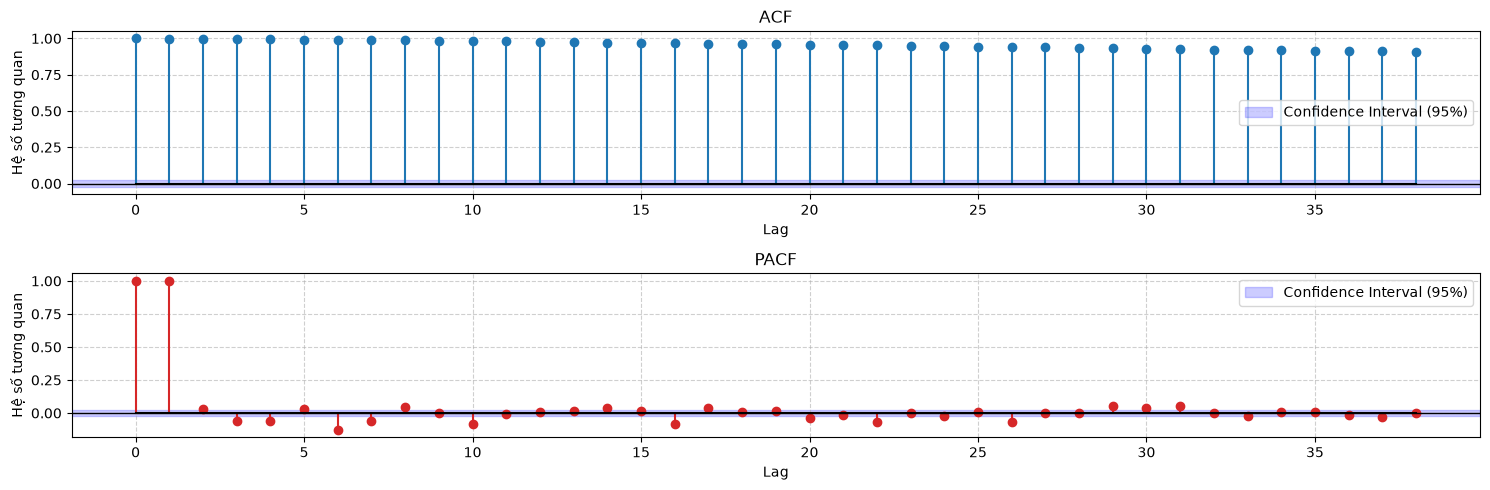

In [59]:
init_acf_pacf(df_close_series)

### Đánh giá biểu đồ ACF

- ACF giảm cực kỳ chậm và vẫn duy trì mức tương quan rất cao xuyên suốt 38 lags.
- Điều này cho thấy các giá trị trong quá khứ vẫn có mối tương quan mạnh với giá trị hiện tại, tức ảnh hưởng của quá khứ vẫn được duy trì trong thời gian dài.

### Đánh giá biểu đồ PACF

- Có một cột tại lag 1 đạt giá trị gần bằng 1.0.
- Sau đó, giá trị PACF lập tức giảm xuống gần bằng 0.
- Các lag tiếp theo đều có giá trị tương đối thấp và hầu như nằm trong dải tin cậy (*confidence interval*).

### Tổng kết

=> Đây là dấu hiệu điển hình gợi ý mô hình **Random Walk (Bước ngẫu nhiên)**, trong đó giá trị hiện tại được xác định bằng giá trị ở thời điểm trước đó cộng với một thành phần nhiễu ngẫu nhiên (*random noise*).


In [60]:
def rolling_stat(series:pd.Series, window_sizes: list = [7, 30, 90]):

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex='all')

    axes[0].plot(series.index, series, label='Origin', color='lightgray', alpha=0.6)
    for w in window_sizes:
        rolling_mean = series.rolling(window=w).mean()
        axes[0].plot(series.index, rolling_mean, label=f'Rolling Mean {w}D')

    axes[0].set_title('Rolling Mean')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    for w in window_sizes:
        rolling_std = series.rolling(window=w).std()
        axes[1].plot(series.index, rolling_std, label=f'Rolling Std {w}D')

    axes[1].set_title('Rolling Standard Deviation')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
        

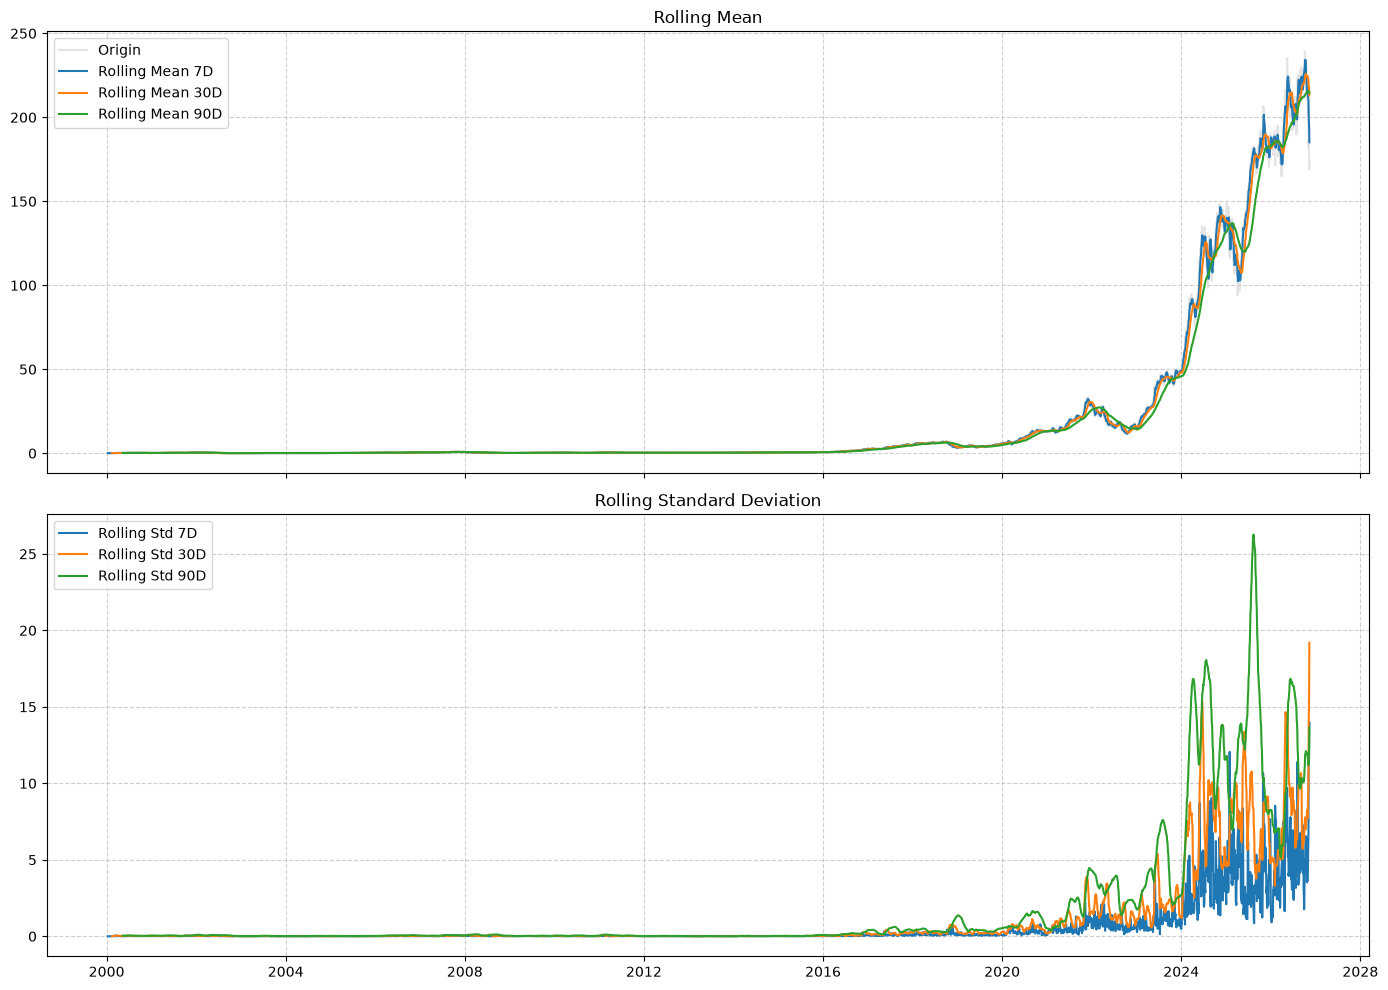

In [61]:
rolling_stat(df_close_series)

- Window size càng lớn thì đường biểu diễn càng mượt (*smooth*), ít dao động gắt và triệt tiêu được nhiều nhiễu (*noise*) ngắn hạn hơn.

### Đánh giá Rolling Mean

- Window size 90 gần như luôn có giá trị thấp nhất, tiếp đến là 30 và cuối cùng là 7.
- Window size 7 cho thấy khả năng bám sát giá thực tế tốt hơn, đồng thời thể hiện rõ các biến động ngắn hạn thông qua những cú giật.
- Trong khi đó, window size càng lớn thì mức độ phản ứng với giá hiện tại càng chậm.
- Cả 3 window size đều cho thấy xu hướng tăng của chuỗi thời gian.

**Kết luận:** Các đường Rolling Mean không dao động quanh một mốc cố định mà có xu hướng tăng mạnh về cuối giai đoạn.

### Đánh giá Rolling Std

- Window size 7 thể hiện sự biến động ngắn hạn rõ nhất, tiếp đến là 30 và 90.
- Window size 90 có xu hướng duy trì quán tính, có thể quan sát rõ trong giai đoạn 2024–2028.
- Đường Rolling Std 90D cũng đạt giá trị tuyệt đối cao nhất.

**Kết luận:** Ở giai đoạn đầu, độ lệch chuẩn gần như nằm sát mốc 0. Tuy nhiên, về những năm cuối, biên độ dao động phình to đáng kể.

### Tổng kết

=> Chuỗi thời gian thể hiện tính không dừng (*non-stationary*) rõ rệt, với hai đặc điểm chính:
- **Mean không ổn định:** Xuất hiện xu hướng tăng (*trend*).
- **Variance không ổn định:** Phương sai có xu hướng tăng và biên độ dao động ngày càng mở rộng.

### Kết luận
- Phải thực hiện tiền xử lí trước khi thực hiện các thao tác phực tạp sau

### Tạo khuyết theo cơ chế MCAR (Missing Completely At Random)
- Ngẫu nhiên đục các khoảng trống, không theo quy luật nào hay phu thuộc vào yếu tố nào khác.


In [62]:
# Dùng phân phối dều (Uniform Distribution)

def fault_injection(series: pd.Series, missing_rate: float = 0.5):
    se_fault = series.copy()

    np.random.seed(42)

    n_missing = int(len(series) * missing_rate)

    # Ngẫu nhiên ko hoàn lại
    missing_indices = np.random.choice(series.index, size=n_missing, replace=False)

    se_fault.loc[missing_indices] = np.nan

    print(f"Tỉ lệ khuyết thực tế{se_fault.isna().mean(): .2%}")

    return se_fault, missing_indices

In [63]:
se_fault, missing_indices = fault_injection(df_close_series)

Tỉ lệ khuyết thực tế 50.00%


### Forward Fill
- Dữ liệu bị thiếu sẽ được thay thế trước tiếp từ giá trị gần nhất trước đó.
- Giả định trạng thái của hệ thống hoặc chuỗi thời gian không thay đổi khi có 1 phép đo mới được ghi nhận.

**Công thức toán học:**
    $$ \hat{y}_{t+i} = y_t \quad \forall i \in \{1, 2, \dots, k\} $$
### Linear Interpolation
- Nội suy tuyến tính bằng đường thằng nối giữa chỉ 2 điểm.
- Giả định tốc độ thay đổi (đạo hàm) là hằng số
Cho hai điểm dữ liệu đã biết là $(x_0, y_0)$ và $(x_1, y_1)$ với $x_0 < x < x_1$. Giá trị nội suy $y$ tại vị trí $x$ được tính theo công thức:

$$y = y_0 + (x - x_0) \frac{y_1 - y_0}{x_1 - x_0}$$
### Polynomial interpolation
- Nội suy đa thức sử dụng đa thực bậc n

(Bậc 2 - Quadratic)
Cần 3 điểm dữ liệu đã biết: $(t_0, y_0), (t_1, y_1), (t_2, y_2)$. 
Công thức khai triển đa thức bậc 2 đi qua 3 điểm này là:

**Công thức toán học:**
$$ 
\begin{aligned}
\hat{y}(t) = P_2(t) &= y_0 \frac{(t - t_1)(t - t_2)}{(t_0 - t_1)(t_0 - t_2)} \\
&+ y_1 \frac{(t - t_0)(t - t_2)}{(t_1 - t_0)(t_1 - t_2)} \\
&+ y_2 \frac{(t - t_0)(t - t_1)}{(t_2 - t_0)(t_2 - t_1)}
\end{aligned}
$$

(Bậc 3 - Cubic)
Cần 4 điểm dữ liệu đã biết: $(t_0, y_0), (t_1, y_1), (t_2, y_2), (t_3, y_3)$. 
Công thức khai triển đa thức bậc 3 đi qua 4 điểm này là:

**Công thức toán học:**
$$ 
\begin{aligned}
\hat{y}(t) = P_3(t) &= y_0 \frac{(t - t_1)(t - t_2)(t - t_3)}{(t_0 - t_1)(t_0 - t_2)(t_0 - t_3)} \\
&+ y_1 \frac{(t - t_0)(t - t_2)(t - t_3)}{(t_1 - t_0)(t_1 - t_2)(t_1 - t_3)} \\
&+ y_2 \frac{(t - t_0)(t - t_1)(t - t_3)}{(t_2 - t_0)(t_2 - t_1)(t_2 - t_3)} \\
&+ y_3 \frac{(t - t_0)(t - t_1)(t - t_2)}{(t_3 - t_0)(t_3 - t_1)(t_3 - t_2)}
\end{aligned}
$$

### Cubic Spline
- Nối 2 điểm lại với nhau bằng đa thức bậc 3 riêng lẽ cho từng đoạn.

Phương trình hàm đa thức bậc 3 cho từng đoạn dữ liệu (từ $t_i$ đến $t_{i+1}$):

**Công thức toán học:**
$$ S_i(t) = a_i + b_i(t - t_i) + c_i(t - t_i)^2 + d_i(t - t_i)^3 $$

Các ràng buộc hệ phương trình để giải hệ số $a_i, b_i, c_i, d_i$:
1. **Nội suy:** $S_i(t_i) = y_i$ và $S_i(t_{i+1}) = y_{i+1}$
2. **Liên tục bậc 1:** $S'_i(t_{i+1}) = S'_{i+1}(t_{i+1})$
3. **Liên tục bậc 2:** $S''_i(t_{i+1}) = S''_{i+1}(t_{i+1})$
4. **Biên (Natural Spline):** $S''_0(t_0) = 0$ và $S''_{n-1}(t_n) = 0$

In [64]:
# Forward Fill
se_ff = se_fault.ffill()

# Linear Interpolation
se_p1 = se_fault.interpolate(method='polynomial', order=1)

# Quadratic Interpolation
se_p2 = se_fault.interpolate(method='polynomial', order=2)

# Cubic Interpolation
se_p3 = se_fault.interpolate(method='polynomial', order=3)

# Spline
se_spline = se_fault.interpolate(method='spline', order=3)

### MAE (Mean Absolute Error - Sai số tuyệt đối trung bình)

**Công thức toán học:**

$$ \text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i| $$

Trong đó:
* $n$: Số lượng điểm dữ liệu bị thiếu cần đánh giá (ví dụ: 5% lượng dữ liệu bị che).
* $y_i$: Giá trị gốc thực tế tại điểm thứ $i$ (Ground Truth).
* $\hat{y}_i$: Giá trị được nội suy / điền khuyết bởi mô hình tại điểm thứ $i$.



### RMSE (Root Mean Squared Error - Căn bậc hai sai số toàn phương trung bình)


**Công thức toán học:**

$$ \text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2} $$

Trong đó:
* $n$: Số lượng điểm dữ liệu được đánh giá.
* $y_i$: Giá trị gốc thực tế tại điểm thứ $i$.
* $\hat{y}_i$: Giá trị được nội suy tại điểm thứ $i$.

In [65]:
def calc_mae(y_true: pd.Series, y_pred: pd.Series, indices: list = None):
    if indices is not None:
        return (y_true[indices] - y_pred[indices]).abs().mean()
    else:
        return (y_true - y_pred).abs().mean()

def calc_rmse(y_true: pd.Series, y_pred: pd.Series, indices: list = None):
    if indices is not None:
        return np.sqrt(((y_true[indices] - y_pred[indices]) ** 2).mean())
    else:
        return np.sqrt(((y_true - y_pred) ** 2).mean())

In [66]:
# TÍnh MAE và RMSE cho từng phương pháp điền khuyết
ff_mae, ff_rmse = calc_mae(df_close_series, se_ff, missing_indices), calc_rmse(df_close_series, se_ff, missing_indices)

p1_mae, p1_rmse = calc_mae(df_close_series, se_p1, missing_indices), calc_rmse(df_close_series, se_p1, missing_indices)

p2_mae, p2_rmse = calc_mae(df_close_series, se_p2, missing_indices), calc_rmse(df_close_series, se_p2, missing_indices)

p3_mae, p3_rmse = calc_mae(df_close_series, se_p3, missing_indices), calc_rmse(df_close_series, se_p3, missing_indices)

spline_mae, spline_rmse = calc_mae(df_close_series, se_spline), calc_rmse(df_close_series, se_spline)

In [67]:
print(f"Forward Fill: MAE ={ff_mae: .4f}, RMSE ={ff_rmse: .4f}")
print(f"Linear Interpolation: MAE ={p1_mae: .4f}, RMSE ={p1_rmse: .4f}")
print(f"Quadratic Interpolation: MAE ={p2_mae: .4f}, RMSE ={p2_rmse: .4f}")
print(f"Cubic Interpolation: MAE ={p3_mae: .4f}, RMSE ={p3_rmse: .4f}")
print(f"Cubic Spline: MAE ={spline_mae: .4f}, RMSE ={spline_rmse: .4f}")

Forward Fill: MAE = 0.6088, RMSE = 2.0776
Linear Interpolation: MAE = 0.3890, RMSE = 1.2431
Quadratic Interpolation: MAE = 0.4733, RMSE = 1.5499
Cubic Interpolation: MAE = 0.4826, RMSE = 1.5852
Cubic Spline: MAE = 0.3270, RMSE = 1.1287


### Đánh giá

- Ta dễ dàng thấy Cubic Spline cho ra kết quả tốt nhất bởi khả năng làm mịn các đoạn bằng hàm bậc 3 giúp làm giảm loss

- Forward Fill cho ra giá trị tệ nhất bởi vì đặc điểm của phương pháp này chỉ đúng khi giá trị duy trì trạng thái không đổi

- Đáng ngạc nhiên hơn khi mà nội suy bậc 1 lại tốt hơn so với bậc 2 và 3, có lẽ vì hàm bậc 2,3 lại có xu hướng dao động mạnh hơn hàm bậc 1

Sau khi điền khuyết ta có thể tính được phần dư:

$$
Residual = y_{true} - y_{imputed}
$$
- Nội suy tốt sẽ cho ra phần dư chỉ còn mang tính ngẫu nhiên không có quy luật hệ thống nào

### Kiểm định Ljung-Box:
- Kiểm định Ljung-Box là một kiểm định thống kê được sử dụng để xác định xem liệu một chuỗi thời gian có tồn tại hiện tượng tự tương quan (autocorrelation) ở bất kỳ nhóm độ trễ (lags) nào hay không.

**Lý thuyết:**
Kiểm định Ljung-Box được sử dụng để kiểm tra xem một chuỗi thời gian có tồn tại hiện tượng **tự tương quan (autocorrelation)** ở các độ trễ (lags) hay không. Trong bài toán đánh giá mô hình điền khuyết (imputation) hoặc dự báo, kiểm định này được áp dụng lên phần dư (residuals). Nếu phần dư chỉ là nhiễu trắng (White Noise), phương pháp điền khuyết đã nắm bắt tốt các quy luật của dữ liệu; nếu phần dư có tự tương quan, phương pháp này đã bỏ sót một vài cấu trúc hệ thống.

**Cặp giả thuyết thống kê:**
*   **Giả thuyết không ($H_0$):** Phần dư được phân phối độc lập (Không có tự tương quan cho đến độ trễ $h$ – Dữ liệu là nhiễu trắng).
*   **Giả thuyết đối ($H_1$):** Phần dư không phân phối độc lập (Tồn tại tự tương quan ở ít nhất một độ trễ – Dữ liệu có tính quy luật).

**Công thức toán học:**
Chỉ số kiểm định $Q$ (Test Statistic) cho độ trễ $h$ được tính bằng công thức:

$$ Q = n(n+2) \sum_{k=1}^{h} \frac{\hat{\rho}_k^2}{n-k} $$

Trong đó:
*   $n$: Kích thước mẫu (số lượng quan sát).
*   $h$: Số lượng độ trễ (lags) tối đa được kiểm tra.
*   $\hat{\rho}_k$: Hệ số tự tương quan mẫu (sample autocorrelation) tại độ trễ $k$.

Giá trị $Q$ tuân theo phân phối Chi-bình phương ($\chi^2$) với $h$ bậc tự do.

**Kết quả P-value (với mức ý nghĩa $\alpha = 0.05$):**
*   **P-value > 0.05 (Chưa đủ cơ sở bác bỏ $H_0$):** Phần dư không có tự tương quan đáng kể, các sai số mang tính ngẫu nhiên. Đây là dấu hiệu cho thấy thuật toán điền khuyết hoạt động hiệu quả.
*   **P-value $\le$ 0.05 (Bác bỏ $H_0$):** Tồn tại tự tương quan trong phần dư. Thuật toán điền khuyết đã tạo ra các sai số có quy luật lặp lại, cho thấy mô hình chưa mô phỏng đúng động lực học của chuỗi dữ liệu gốc.


In [68]:
from statsmodels.stats.diagnostic import acorr_ljungbox
max_lag = calc_max_lag(df_close_series)

residuals_ff = df_close_series - se_ff
residuals_li = df_close_series - se_p1
residuals_qi = df_close_series - se_p2
residuals_ci = df_close_series - se_p3
residuals_cs = df_close_series - se_spline

lb_ff = acorr_ljungbox(residuals_ff.dropna(), lags=[max_lag], return_df=True)
lb_li = acorr_ljungbox(residuals_li.dropna(), lags=[max_lag], return_df=True)
lb_qi = acorr_ljungbox(residuals_qi.dropna(), lags=[max_lag], return_df=True)
lb_ci = acorr_ljungbox(residuals_ci.dropna(), lags=[max_lag], return_df=True)
lb_cs = acorr_ljungbox(residuals_cs.dropna(), lags=[max_lag], return_df=True)

In [69]:
print(f"Forward Fill:")
print(lb_ff)
print(f"Linear Interpolation:")
print(lb_li)
print(f"Quadratic Interpolation:")
print(lb_qi)
print(f"Cubic Interpolation:")
print(lb_ci)
print(f"Cubic Spline:")
print(lb_cs)

Forward Fill:
        lb_stat  lb_pvalue
38  2569.892963        0.0
Linear Interpolation:
        lb_stat      lb_pvalue
38  1220.885827  1.722890e-231
Quadratic Interpolation:
        lb_stat  lb_pvalue
38  2363.890855        0.0
Cubic Interpolation:
        lb_stat  lb_pvalue
38  2629.092318        0.0
Cubic Spline:
        lb_stat  lb_pvalue
38  1687.704851        0.0


- Các phần dư có tính tự tương quan
- Vì ta chỉ lấy có 5% dữ liệu khuyết và dùng nội suy
- Trong khi đó 95% dữ liệu có giá trị đúng
- Phần dư ta tính ra được 95% luôn bằng 0
- Kiểm định Ljung-Box vì thế cho rằng giá trị ngày mai được định bởi hôm nay, tạo nên hiện tượng tự tương quan

### Thử chỉ trên 5% dữ liệu khuyết

In [70]:
residuals_ff = df_close_series[missing_indices] - se_ff[missing_indices]
residuals_li = df_close_series[missing_indices] - se_p1[missing_indices]
residuals_qi = df_close_series[missing_indices] - se_p2[missing_indices]
residuals_ci = df_close_series[missing_indices] - se_p3[missing_indices]
residuals_cs = df_close_series[missing_indices] - se_spline[missing_indices]

lb_ff = acorr_ljungbox(residuals_ff.dropna(), lags=[max_lag], return_df=True)
lb_li = acorr_ljungbox(residuals_li.dropna(), lags=[max_lag], return_df=True)
lb_qi = acorr_ljungbox(residuals_qi.dropna(), lags=[max_lag], return_df=True)
lb_ci = acorr_ljungbox(residuals_ci.dropna(), lags=[max_lag], return_df=True)
lb_cs = acorr_ljungbox(residuals_cs.dropna(), lags=[max_lag], return_df=True)

print(f"Forward Fill:")
print(lb_ff)
print(f"Linear Interpolation:")
print(lb_li)
print(f"Quadratic Interpolation:")
print(lb_qi)
print(f"Cubic Interpolation:")
print(lb_ci)
print(f"Cubic Spline:")
print(lb_cs)

Forward Fill:
      lb_stat  lb_pvalue
38  35.511293   0.585103
Linear Interpolation:
      lb_stat  lb_pvalue
38  30.601048   0.797627
Quadratic Interpolation:
      lb_stat  lb_pvalue
38  36.867748   0.521705
Cubic Interpolation:
      lb_stat  lb_pvalue
38  34.896081   0.613759
Cubic Spline:
     lb_stat  lb_pvalue
38  44.99596    0.20231


- Khi thử chỉ 5% điểm khuyết ta lại thấy các phương pháp nội suy cho rằng phần dư không có tự tương quan (p-value > 0.05)
- Nhưng vì ta chọn random indices theo cơ chế MCAR làm mất đi tính chất timeseries khiến sai số của chúng hoàn toàn độc lập và không có bất kì tương quan nào với nhau
### -> Tạo ra ảo giác thống kê: vì làm mất đi tính chất liên tục

---
### Kiểm định ADF (Augmented Dickey-Fuller)
- Dựa trên mô hình tự hồi quy (Autogressive - AR)
- Kiểm tra xem chuỗi có tồn tại nghiệm **'đơn vị'** hay không, nếu có quá trình đó là Random Walk
- Thêm vào các độ trễ vị phân để khử tự tương quan trong phần sai số.


#### 1. Cặp giả định thống kê
*   **$H_0$:** $\gamma = 0$ (Chuỗi chứa nghiệm đơn vị - Unit Root $\rightarrow$ Chuỗi **không dừng**).
*   **$H_1$:** $\gamma < 0$ (Chuỗi không có nghiệm đơn vị $\rightarrow$ Chuỗi **dừng** hoặc dừng quanh xu hướng).

---

#### 2. Công thức toán học

Phương trình hồi quy OLS mở rộng với $p$ độ trễ vi phân:

$$ \Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta y_{t-i} + \epsilon_t $$

Trong đó:
*   $\Delta y_t = y_t - y_{t-1}$: Sai phân bậc 1 của chuỗi tại thời điểm $t$.
*   $\alpha$: Hệ số chặn (Drift/Constant).
*   $\beta t$: Xu hướng thời gian xác định (Deterministic Trend).
*   $\gamma$: Hệ số kiểm định trọng tâm ($\gamma = \rho - 1$, với $\rho$ là hệ số tự hồi quy bậc 1).
*   $p$: Số bậc trễ được bổ sung để loại bỏ tự tương quan của phần dư (xác định qua tiêu chuẩn AIC hoặc BIC).
*   $\epsilon_t$: Phần dư ngẫu nhiên (White Noise).

Chỉ số thống kê kiểm định (ADF Test Statistic / $\tau$-statistic) được tính bằng:

$$ \tau = \frac{\hat{\gamma}}{\text{SE}(\hat{\gamma})} $$

Trong đó $\hat{\gamma}$ là ước lượng OLS của $\gamma$ và $\text{SE}(\hat{\gamma})$ là sai số chuẩn của ước lượng này.

---

#### 3. P-value và Kết luận kết quả

Do giả định $H_0$ chứa nghiệm đơn vị, giá trị thống kê $\tau$ **không** tuân theo phân phối Student-$t$ chuẩn mà tuân theo phân phối bất đối xứng **Dickey-Fuller (MacKinnon distribution)**

*   **P-value $\le \alpha$ = 0.05:**
    *   Bác bỏ giả thuyết không $H_0$.
    *   **Kết luận:** Có đủ cơ sở thống kê để khẳng định chuỗi **dừng** (Stationary).
*   **P-value $> \alpha$ = 0.05:**
    *   Chưa đủ bằng chứng thống kê để bác bỏ $H_0$.
    *   **Kết luận:** Chuỗi **không dừng** (Non-stationary, tồn tại Unit Root)

In [71]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller

def adf_test(series: pd.Series):
    
    series = series.dropna()

    adf_res = adfuller(series, autolag='AIC', result_object=True)

    return adf_res.statistic, adf_res.pvalue



### Kiểm định PP (Phillips-Perron)
- Cùng mục dích và giả thuyết giống ADF
- Thay vì thêm vi phân bậc trễ, PP giữ nguyên phương trình Dickey-Fuller chuẩn (chỉ AR(1))
- Sư dụng phương pháp phi tham số để hiệu chỉnh thẳng vào đại lượng thống kê (t-stastic)

#### 1. Cặp giả thuyết thống kê
*   **$H_0$ (Giả thuyết không):** $\gamma = 0$ (Chuỗi chứa nghiệm đơn vị - Unit Root $\rightarrow$ Chuỗi **không dừng**).
*   **$H_1$ (Giả thuyết đối):** $\gamma < 0$ (Chuỗi không có nghiệm đơn vị $\rightarrow$ Chuỗi **dừng** hoặc dừng quanh xu hướng).

---

#### 2. Công thức toán học

Phương trình hồi quy phụ trợ cơ bản (dạng AR(1) chuẩn, không thêm trễ sai phân):

$$ \Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \epsilon_t $$

Trong đó:
*   $\Delta y_t = y_t - y_{t-1}$: Sai phân bậc 1 của chuỗi tại thời điểm $t$.
*   $\alpha$: Hệ số chặn (Drift).
*   $\beta t$: Xu hướng thời gian xác định (Deterministic Trend).
*   $\gamma$: Hệ số kiểm định trọng tâm ($\gamma = \rho - 1$).
*   $\epsilon_t$: Phần dư (cho phép tồn tại tự tương quan và phương sai thay đổi - Heteroskedasticity).

Thay vì thêm các biến trễ vi phân $\Delta y_{t-i}$ vào mô hình như ADF, kiểm định PP giữ nguyên phương trình bậc 1 và dùng bộ ước lượng **Newey-West HAC** để ước lượng phương sai dài hạn (Long-run variance) $\sigma^2$ và phương sai tức thời (Contemporary variance) $\sigma_0^2$:

$$ \hat{\sigma}_0^2 = \frac{1}{T} \sum_{t=1}^{T} \hat{\epsilon}_t^2 $$

$$ \hat{\sigma}^2 = \hat{\sigma}_0^2 + \frac{2}{T} \sum_{k=1}^{l} w(k, l) \sum_{t=k+1}^{T} \hat{\epsilon}_t \hat{\epsilon}_{t-k} $$

*(với $w(k, l) = 1 - \frac{k}{l+1}$ là trọng số hạt nhân Bartlett kernel và $l$ là độ trễ cắt Newey-West).*

Chỉ số kiểm định hiệu chỉnh phi tham số ($Z_\tau$-statistic hoặc PP $t$-statistic) được tính bằng:

$$ Z_\tau = \tau \left( \frac{\hat{\sigma}_0}{\hat{\sigma}} \right) - \frac{T (\hat{\sigma}^2 - \hat{\sigma}_0^2) \cdot \text{SE}(\hat{\gamma})}{2 \hat{\sigma} \cdot s} $$

Trong đó:
*   $\tau = \frac{\hat{\gamma}}{\text{SE}(\hat{\gamma})}$: Thống kê $t$ thông thường từ ước lượng OLS.
*   $s$: Độ lệch chuẩn mẫu của phần dư hồi quy OLS.
*   $T$: Kích thước mẫu quan sát.

---

#### 3. P-value và Kết luận kết quả

Chỉ số kiểm định $Z_\tau$ tuân theo cùng phân phối giới hạn với thống kê ADF (**phân phối Dickey-Fuller / bảng tra MacKinnon**):

*   **P-value $\le \alpha$ = 0.05:**
    *   Bác bỏ giả thuyết không $H_0$.
    *   **Kết luận:** Có đủ cơ sở thống kê để khẳng định chuỗi **dừng** (Stationary).
*   **P-value $> \alpha$ = 0.05:**
    *   Chưa đủ bằng chứng thống kê để bác bỏ $H_0$.
    *   **Kết luận:** Chuỗi **không dừng** (Non-stationary, tồn tại Unit Root)

In [72]:
from arch.unitroot import PhillipsPerron

def pp_test(series: pd.Series):

    pp_test = PhillipsPerron(series.dropna())
    pp_stat = pp_test.stat
    pp_pvalue = pp_test.pvalue

    return pp_stat, pp_pvalue


### Kiểm định KPSS (Kwiatkowski-Phillips-Schmidt-Shin)
- Khác hoàn toàn ADF và PP
- Giả định chuỗi được cấu thành từ 3 phần: xu hướng tất định, bước ngẫu nhiên, sai số dừng
#### 1. Cặp giả thuyết thống kê (Đảo ngược so với ADF và PP)
*   **$H_0$ (Giả thuyết không):** Chuỗi **dừng** quanh mức trung bình hoặc dừng quanh một xu hướng tất định (Trend-Stationary).
*   **$H_1$ (Giả thuyết đối):** $\sigma_u^2 > 0$ (Tồn tại thành phần bước ngẫu nhiên $\rightarrow$ Chuỗi chứa nghiệm đơn vị, **không dừng**).

---

#### 2. Công thức toán học

KPSS giả định chuỗi thời gian $y_t$ được phân rã thành ba thành phần:

$$ y_t = \xi t + r_t + \epsilon_t $$

Trong đó:
*   $\xi t$: Xu hướng tất định (Deterministic Trend). Nếu kiểm định tính dừng quanh mức trung bình (Level Stationary), bỏ qua số hạng này ($\xi = 0$).
*   $r_t$: Thành phần bước ngẫu nhiên (Random Walk), tuân theo quy trình:
    $$ r_t = r_{t-1} + u_t \quad \text{với } u_t \sim \text{iid}(0, \sigma_u^2) $$
*   $\epsilon_t$: Phần dư dừng (Stationary Error).

**Cơ chế kiểm định:**
*   Nếu $\sigma_u^2 = 0$, quá trình $r_t$ suy biến thành hằng số $r_0$ (chính là hệ số chặn/intercept $\alpha$). Khi đó chuỗi chỉ còn là xu hướng cộng với nhiễu dừng $\epsilon_t$, tức chuỗi là **dừng**.
*   Nếu $\sigma_u^2 > 0$, thành phần $r_t$ biến thiên theo một bước ngẫu nhiên, tạo ra nghiệm đơn vị khiến chuỗi **không dừng**.

**Đại lượng kiểm định (LM - Lagrange Multiplier Statistic):**
Hồi quy $y_t$ theo hằng số (hoặc hằng số + xu hướng) bằng OLS để thu được phần dư $e_t$. Tính chuỗi tổng tích lũy của phần dư:

$$ S_t = \sum_{i=1}^{t} e_i \quad (t = 1, 2, \dots, T) $$

Chỉ số kiểm định LM được xác định bởi:

$$ \text{LM} = \frac{\sum_{t=1}^{T} S_t^2}{T^2 \cdot \hat{\sigma}^2_\infty} $$

Trong đó:
*   $T$: Kích thước mẫu quan sát.
*   $\hat{\sigma}^2_\infty$: Ước lượng phi tham số nhất quán Newey-West (HAC) của phương sai dài hạn (Long-run variance) của $e_t$:
    $$ \hat{\sigma}^2_\infty = \hat{\gamma}_0 + 2 \sum_{k=1}^{l} \left( 1 - \frac{k}{l+1} \right) \hat{\gamma}_k $$
    *(với $\hat{\gamma}_k$ là hiệp phương sai mẫu tại độ trễ $k$, và $l$ là độ rộng cửa sổ Bartlett kernel).*

---

#### 3. P-value và Kết luận kết quả

Chỉ số thống kê LM được so sánh với các giá trị tới hạn (Critical Values) của phân phối KPSS tiệm cận:

*   **P-value $< \alpha$ (thường chọn $\alpha = 0.05$ hay $\text{LM} > \text{Critical Value}_{5\%}$):**
    *   Bác bỏ giả thuyết không $H_0$.
    *   **Kết luận:** Có đủ cơ sở thống kê để khẳng định chuỗi **không dừng** (Non-stationary, tồn tại Unit Root).
*   **P-value $\ge \alpha$ ($\text{LM} \le \text{Critical Value}_{5\%}$):**
    *   Chưa đủ bằng chứng để bác bỏ $H_0$.
    *   **Kết luận:** Chuỗi **dừng** (Stationary hoặc Trend-Stationary).

In [73]:
from arch.unitroot.unitroot import KPSS
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    message="Lag selection has changed.*"
)

def kpss_test(series: pd.Series):
    kpss_result = KPSS(series.dropna(), trend='c', lags=None)
    kpss_stat = kpss_result.stat
    kpss_pvalue = kpss_result.pvalue

    return kpss_stat, kpss_pvalue


In [74]:
def stationarity_test(series: pd.Series, alpha: float=0.05):

    # ADF
    adf_stat, adf_pvalue = adf_test(series)

    # PP
    pp_stat, pp_pvalue = pp_test(series)

    # KPSS
    kpss_stat, kpss_pvalue = kpss_test(series)

    print("-----ADF TEST-----")
    print(f"Statistic :{adf_stat}")
    print(f"P-value :{adf_pvalue}")
    print(f"Kết luận (α={alpha})")
    if adf_pvalue > alpha:
        print("-> Chấp nhận H0")
        print("  => Chuỗi KHÔNG DỪNG")
    else:
        print("-> Bác bỏ H0")
        print("  => Chuỗi CÓ DỪNG")

    print("-----PP TEST-----")
    print(f"Statistic :{pp_stat}")
    print(f"P-value :{pp_pvalue}")
    print(f"Kết luận (α={alpha})")
    if pp_pvalue > alpha:
        print("-> Chấp nhận H0")
        print("  => Chuỗi KHÔNG DỪNG")
    else:
        print("-> Bác bỏ H0")
        print("  => Chuỗi CÓ DỪNG")

    print("-----KPSS TEST-----")
    print(f"Statistic :{kpss_stat}")
    print(f"P-value :{kpss_pvalue}")
    print(f"Kết luận (α={alpha})")

    if kpss_pvalue > alpha:
        print("-> Chấp nhận H0")
        print("  => Chuỗi CÓ DỪNG")

    else:
        print("-> Bác bỏ H0")
        print("  => Chuỗi KHÔNG DỪNG")


stationarity_test(df_close_series, 0.05)

-----ADF TEST-----
Statistic :1.5361098236452775
P-value :0.9976526590561683
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi KHÔNG DỪNG
-----PP TEST-----
Statistic :1.205270049371297
P-value :0.9960220927139875
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi KHÔNG DỪNG
-----KPSS TEST-----
Statistic :5.154548300019949
P-value :0.0001
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi KHÔNG DỪNG


## Kết luận
- Cả 3 kiểm thử đều cho ra dữ liệu không có tính dừng

## Các bước thử tiếp theo
1. Box-cox và Log riêng lẻ
2. Thêm sai phân vị bậc 1, 2 cho bước 1 nếu chưa dừng

In [75]:
from scipy import stats

# Box-Cox trước
se_box_cox, best_lambda = stats.boxcox(df_close_series)
se_box_cox = pd.Series(se_box_cox)
stationarity_test(se_box_cox)

-----ADF TEST-----
Statistic :-0.9116306367517285
P-value :0.7841181560992967
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi KHÔNG DỪNG
-----PP TEST-----
Statistic :-1.1496378305550117
P-value :0.6948767447139332
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi KHÔNG DỪNG
-----KPSS TEST-----
Statistic :11.322228065443932
P-value :0.0001
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi KHÔNG DỪNG


In [76]:
# Log
se_log = np.log(df_close_series)
stationarity_test(se_log)

-----ADF TEST-----
Statistic :0.5368291515905125
P-value :0.985950530138296
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi KHÔNG DỪNG
-----PP TEST-----
Statistic :0.4106737966681918
P-value :0.9818897441595917
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi KHÔNG DỪNG
-----KPSS TEST-----
Statistic :10.887428098426824
P-value :0.0001
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi KHÔNG DỪNG


## Đánh giá
- Phương pháp biến đổi Box-cox và Log vẫn chưa cho ra tính dừng

In [77]:
# Sai phân bậc 1 trên Box-cox
box_cox_diff_1 = se_box_cox.diff().dropna()
stationarity_test(box_cox_diff_1)

-----ADF TEST-----
Statistic :-14.014640303208628
P-value :3.6614476285484143e-26
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi CÓ DỪNG
-----PP TEST-----
Statistic :-80.40425103914707
P-value :0.0
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi CÓ DỪNG
-----KPSS TEST-----
Statistic :0.034145938752097885
P-value :0.9609771586457774
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi CÓ DỪNG


In [78]:
# Sai phân bậc 1 trên Log
log_diff_1 = se_log.diff().dropna()
stationarity_test(log_diff_1)

-----ADF TEST-----
Statistic :-14.158093120464455
P-value :2.1042902441144117e-26
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi CÓ DỪNG
-----PP TEST-----
Statistic :-82.80344761356407
P-value :0.0
Kết luận (α=0.05)
-> Bác bỏ H0
  => Chuỗi CÓ DỪNG
-----KPSS TEST-----
Statistic :0.21093833829929623
P-value :0.2477886816083996
Kết luận (α=0.05)
-> Chấp nhận H0
  => Chuỗi CÓ DỪNG


### Kết luận
- Log + Sai phân bậc 1
- Box-cox + Sai phân bậc 1

-> Đều cho ra dữ liệu có tính dừng

### Giải thích
- Box-Cox/Log giúp giữ cho biên độ dao động ổn định
- Trong khi đó sai phân bậc 1,2 triệt tiêu xu hướng đi lên biến chuỗi trend đi lên thành chuỗi dao động ngâu nhiên quanh giá trị trung bình 0
- Cả Mean và Variance lúc này đã thỏa tính dừng


---
# Phân rã chuỗi thời gian (Time Series Decomposition)
- Kĩ thuật giải phẫu chuỗi dữ liệu hôn hợp thành tín hiệu cơ bản để hiểu rõ bản chất nội tại của nó
- Người ta giả định mọi điểm dữ liệu dược cấu thành từ 3 thành phần:
    - Trend-Cycle(T<sub>t</sub> - Xu hướng)
    - Seasonality (S<sub>t</sub> - Tính mùa vụ)
    - Residual/Error (R<sub>t</sub> - Dư/Nhiễu trắng)

## 1. Phân rã Cộng (Additive Decomposition)

* Giả định chuỗi thời gian dược tạo ra bằng cách cộng tuyến tính của 3 thành phần lại với nhau:

    $$Y_t = T_t + S_t + R_t$$

    - Biên độ tính mùa vụ ($S_t$) và phần dư ($R_t$) là hằng số **độc lập** với xu hướng ($T_t$).
    - Nhận biết: dù đường xu hướng đi lên cao hay xuống thấp, chiều cao của đỉnh hay dáy (biện độ dao động) vẫn không đổi

## 2. Phân rã Tích (Multiplicative Decomposition)

* Giả định chuỗi thời gian dược tạo ra bằng cách nhân 3 thành phần lại với nhau:

    $$Y_t = T_t \times S_t \times R_t$$

    - Biên độ tính mùa vụ ($S_t$) và phần dư ($R_t$) **tỷ lệ thuận** với xu hướng ($T_t$)
    - Nhận biết: biên độ dao động phình to ra (tòe ra như cái phễu) khi chuỗi dữ liệu có trend tăng, và thu hẹp lại khi trend giảm

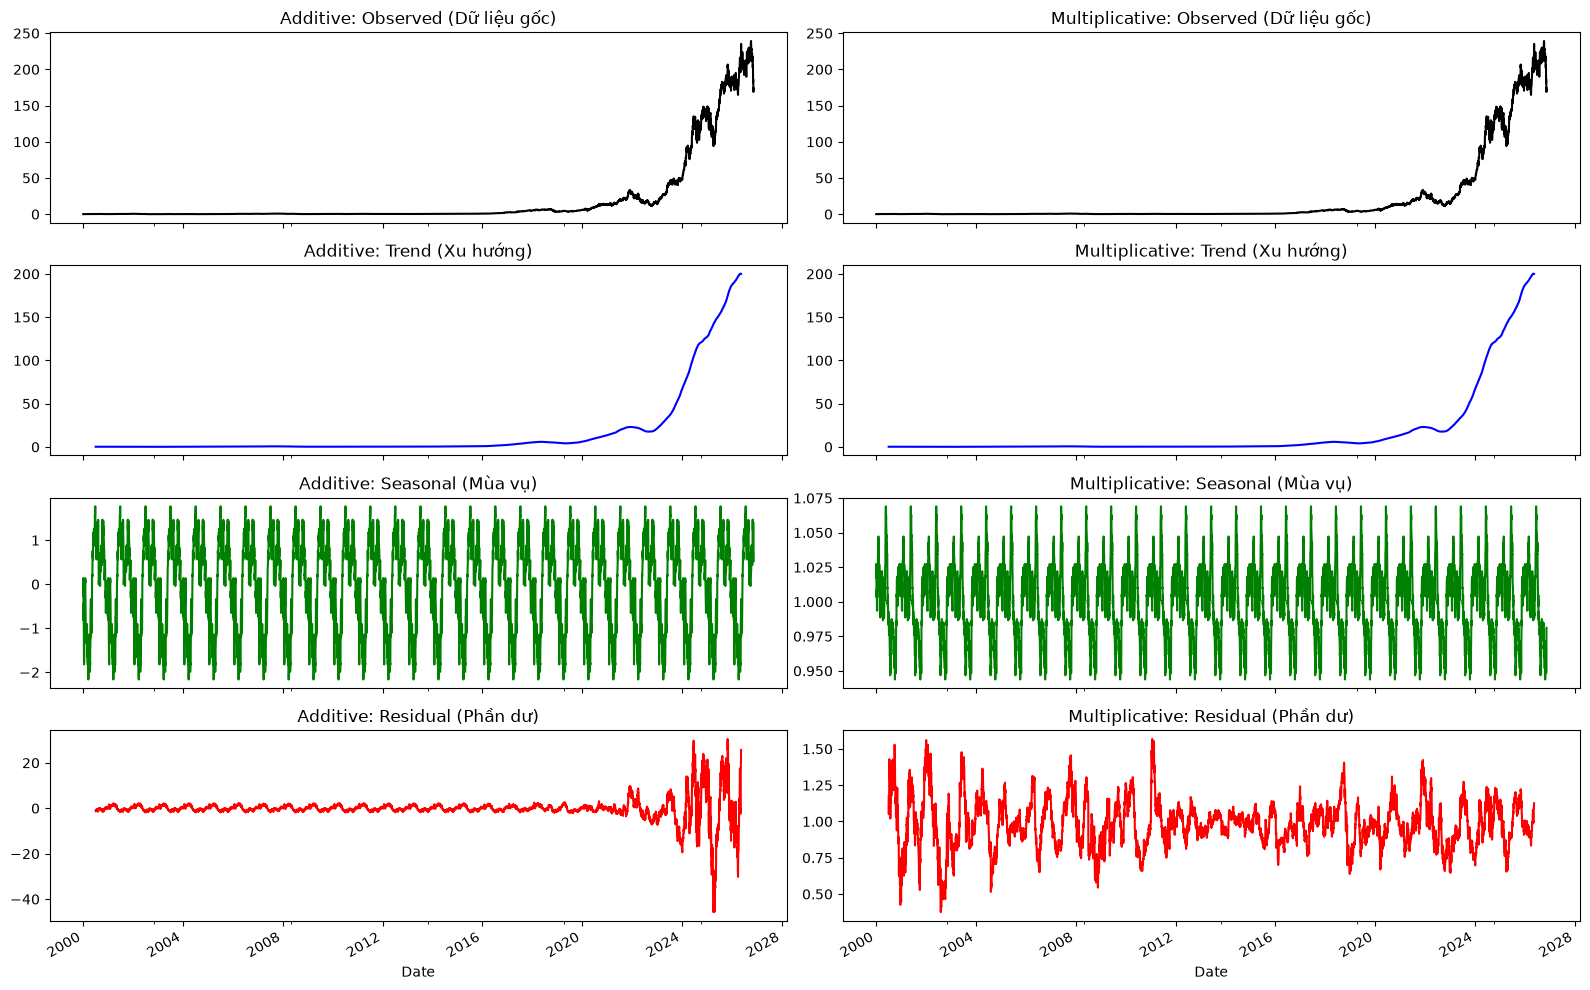

In [79]:
from statsmodels.tsa.seasonal import seasonal_decompose

period = 252
# Additive
decomp_add = seasonal_decompose(df_close_series, model='additive', period=period)

# Multi
decomp_multi = seasonal_decompose(df_close_series, model='multiplicative', period=period)

trend_add = decomp_add.trend
seasonal_add = decomp_add.seasonal
resid_add = decomp_add.resid

# Multiplicative components
trend_multi = decomp_multi.trend
seasonal_multi = decomp_multi.seasonal
resid_multi = decomp_multi.resid

fig, axes = plt.subplots(4, 2, figsize=(16, 10), sharex=True)

# Cột 1: Additive
axes[0, 0].set_title('Additive: Observed (Dữ liệu gốc)')
decomp_add.observed.plot(ax=axes[0, 0], color='black')

axes[1, 0].set_title('Additive: Trend (Xu hướng)')
trend_add.plot(ax=axes[1, 0], color='blue')

axes[2, 0].set_title('Additive: Seasonal (Mùa vụ)')
seasonal_add.plot(ax=axes[2, 0], color='green')

axes[3, 0].set_title('Additive: Residual (Phần dư)')
resid_add.plot(ax=axes[3, 0], color='red')

# Cột 2: Multiplicative
axes[0, 1].set_title('Multiplicative: Observed (Dữ liệu gốc)')
decomp_multi.observed.plot(ax=axes[0, 1], color='black')

axes[1, 1].set_title('Multiplicative: Trend (Xu hướng)')
trend_multi.plot(ax=axes[1, 1], color='blue')

axes[2, 1].set_title('Multiplicative: Seasonal (Mùa vụ)')
seasonal_multi.plot(ax=axes[2, 1], color='green')

axes[3, 1].set_title('Multiplicative: Residual (Phần dư)')
resid_multi.plot(ax=axes[3, 1], color='red')

plt.tight_layout()
plt.show()

### Nhận xét
- Ta có thể thấy tính mùa vụ của 2 phương pháp phân rã với **Additive** là mang giá trị tuyết đối còn **Multiplicative** thì mang giá trị tương đối (%)
- Đây là phương pháp Naive khi chỉ sử dụng Đại số cơ bản và Trung bình cộng, hơn thế nữa phải setup thủ công giá trị **L - chu kì mùa vụ**

## Phần dư
### 1. Additive Residual
- Vì phương pháp này giả định phần dư và tính mùa vụ là độc lập với xu hướng, nghĩa nó phải dao động quanh mean = 0 với biên độ hằng số ổn định
- Nhưng tại 2020 trở đi ta thấy dao động biên động mạnh mẽ (-40 -> +20)
- Cho thấy phương sai của nhiễu tỷ lệ thuận với xu độ lớn của xu hướng.

### 2. Multiplicative Residual
- Với giả định phần dư và tính mùa vụ tỷ lệ thuận với xu hướng
- Ta có thể thấy rõ Residual dàn đều và ổn định, các dao động đều đạn quanh trục 1

---

##  STL Decomposition (Seasonal-Trend decomposition using LOESS)

- Thuật toán phân rã thời gian linh hoạt so với tryền thống

- Sử dụng thuật toán LOESS để liên tục *'trượt'* qua dữ liệu và điều chỉnh biến động đường xu hướng và tính mùa vụ trong đoạn nhỏ.

### 1. LOESS (Locally Estimated Scatterplot Smoothin)

- Thuật toán hồi quy cục bộ
- Sử dụng Window Size để slide qua dữ liệu tại mỗi điểm $x_i$, chỉ xét window size các điểm lân cận
- Vẽ 1 đường hồi quy ngắn chỉ cho riêng cửa số đó

In [80]:
def plot_decomposition(original, trend, sessional, resid, start_date=None, end_date=None):

    if start_date is None:
        start_date = original.index.min()

    if end_date is None:
        end_date = original.index.max()

    original = original.loc[start_date:end_date]
    trend = trend.loc[start_date:end_date]
    sessional = sessional.loc[start_date:end_date]
    resid = resid.loc[start_date:end_date]
    
    fig, axes = plt.subplots(5, 1, figsize=(16, 10), sharex=True)
    fig.suptitle(
        f'Seasonal Decomposition ({start_date:%Y-%m-%d} → {end_date:%Y-%m-%d})',
        fontsize=14
    )

    axes[0].set_title('Observed (Dữ liệu gốc)')
    original.plot(ax=axes[0], color='black')

    axes[1].set_title('Trend (Xu hướng)')
    trend.plot(ax=axes[1], color='blue')

    axes[2].set_title('Seasonal (Mùa vụ)')
    sessional.plot(ax=axes[2], color='green')

    axes[3].set_title('Residual (Phần dư)')
    resid.plot(ax=axes[3], color='red')

    estimated = trend + sessional
    axes[4].set_title('Compare')
    original.plot(ax=axes[4], color='blue')
    estimated.plot(ax=axes[4], color='orange')

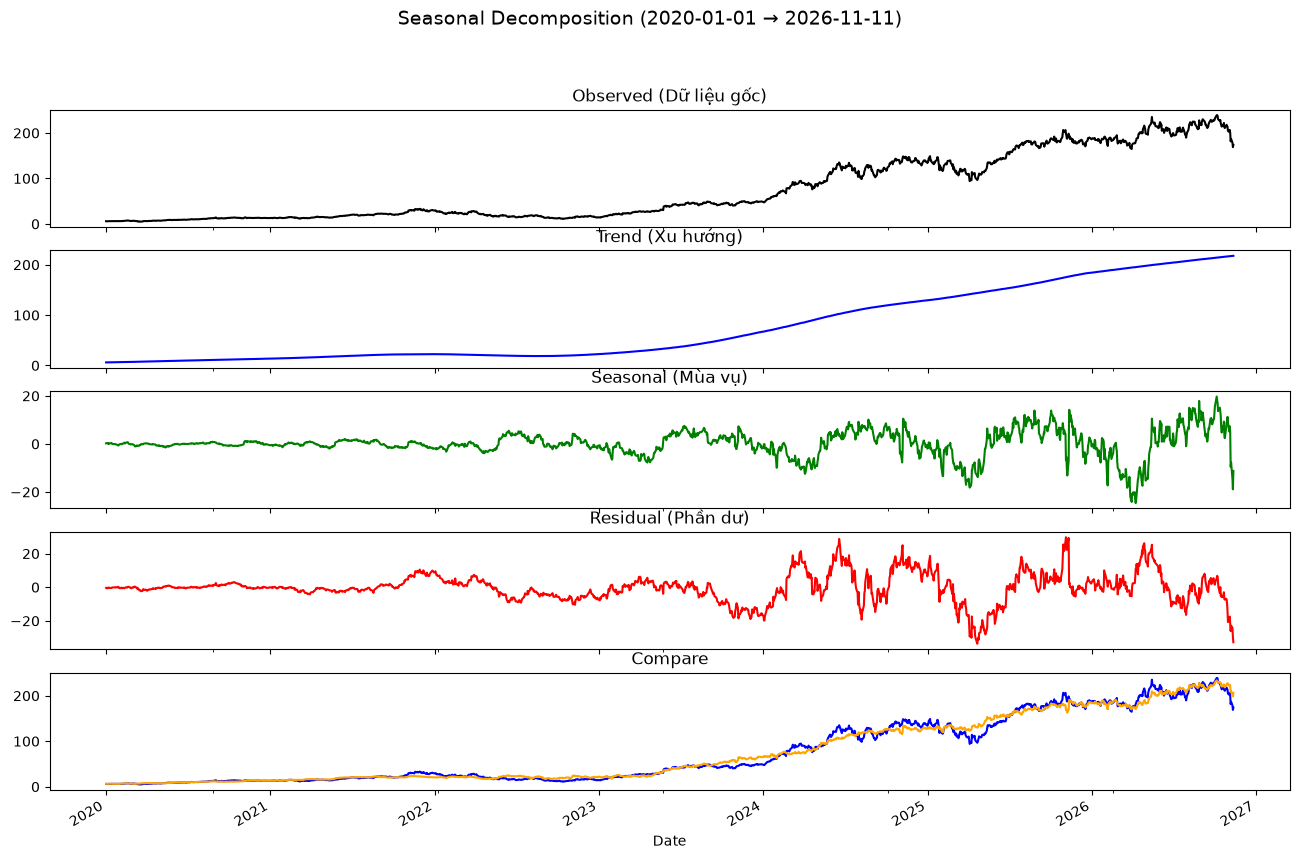

In [81]:
# Yêu cầu 2 tham số: 
# + Chu kì (period) 
# + Sessional(window size) -> Phải là số lẻ
from statsmodels.tsa.seasonal import STL

period = 252
seasonal = 9
stl = STL(df_close_series, period=period, seasonal=seasonal)
stl_res = stl.fit()

stl_trend, stl_seasional, stl_resid = stl_res.trend, stl_res.seasonal, stl_res.resid

plot_decomposition(stl_res.observed, stl_trend, stl_seasional, stl_resid, start_date=pd.Timestamp('2020-01-01'))

## Nhận xét
- Ta có thể thấy khi dùng STL Sessional không còn chỉ là các biên động lặp lại
- Residual vẫn cho thấy sự biến động mạnh mẽ, cho thấy nó có tỷ lệ thuận với xu hướng
- Khi Compare dữ liệu gốc và (trend + sesonal) ta có thể lọc ra các thời điểm anomaly

---
## Plot khoảng giá trị quan sát anomaly

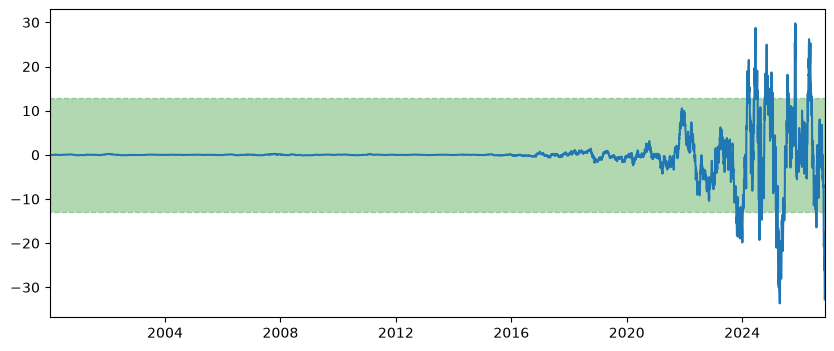

In [82]:
def plot_anomaly_detection(original, resid, coef=3):
    resid_mean = resid.mean()
    resid_dev = resid.std()

    lower = resid_mean - coef * resid_dev
    upper = resid_mean + coef * resid_dev

    min = resid.index.min()
    max = resid.index.max()
    
    plt.figure(figsize=(10, 4))
    plt.plot(resid)
    plt.fill_between([min, max], lower, upper, color='g', alpha = 0.3, linestyle='--')
    plt.xlim(min, max)
    plt.show()

    anomolies = original[(resid < lower) | (resid > upper)]
    return anomolies
anomolies = plot_anomaly_detection(stl_res.observed, stl_resid)

In [83]:
anomolies

Date
2023-10-19     41.975639
2023-10-20     41.263760
2023-10-23     42.847031
2023-10-24     43.532986
2023-10-25     41.654583
                 ...    
2026-11-05    181.600006
2026-11-06    186.639999
2026-11-09    178.669998
2026-11-10    168.889999
2026-11-11    173.729996
Name: Close, Length: 248, dtype: float64

### Ta chọn 1 Anamoly tiêu biểu ra (2026-11-09) để xem tại sao có sự xuất hiện dị biệt này

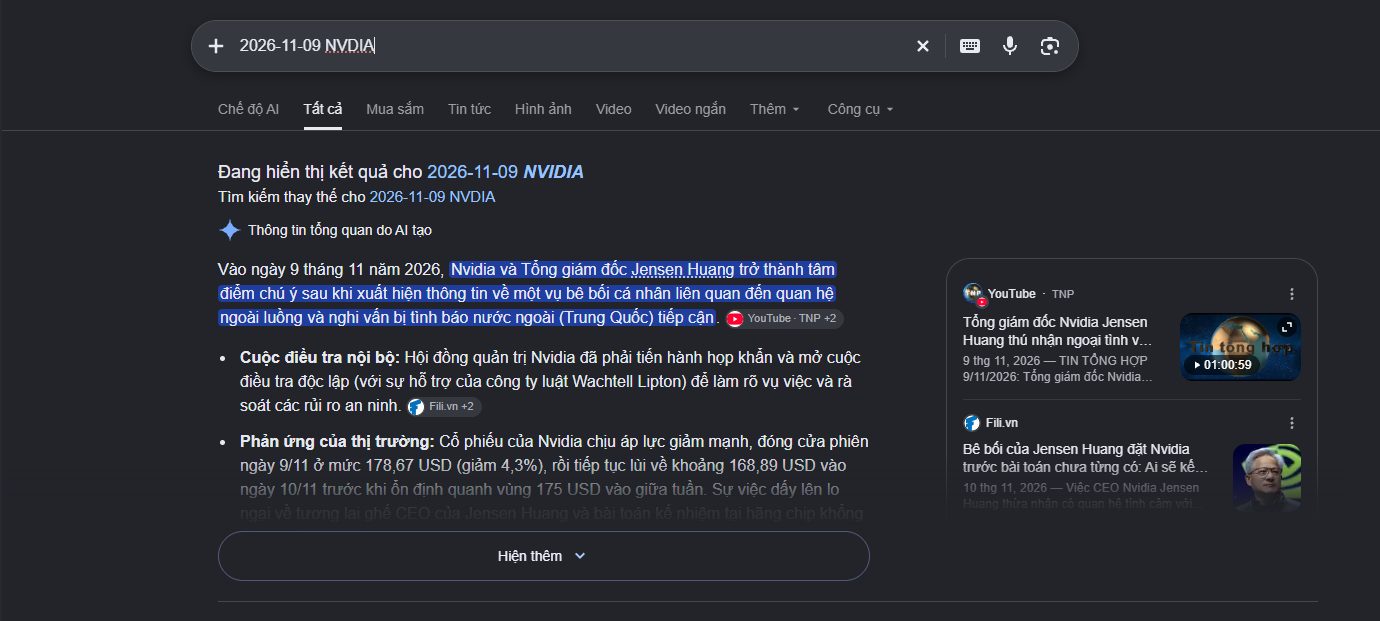

In [84]:
# Lấy 1 khoảng khác
anomolies.loc['2024-01-01':]

Date
2024-01-02     48.028793
2024-01-03     47.431526
2024-01-04     47.859291
2024-01-05     48.955105
2024-01-08     52.101986
                 ...    
2026-11-05    181.600006
2026-11-06    186.639999
2026-11-09    178.669998
2026-11-10    168.889999
2026-11-11    173.729996
Name: Close, Length: 208, dtype: float64

### 2024-01-08

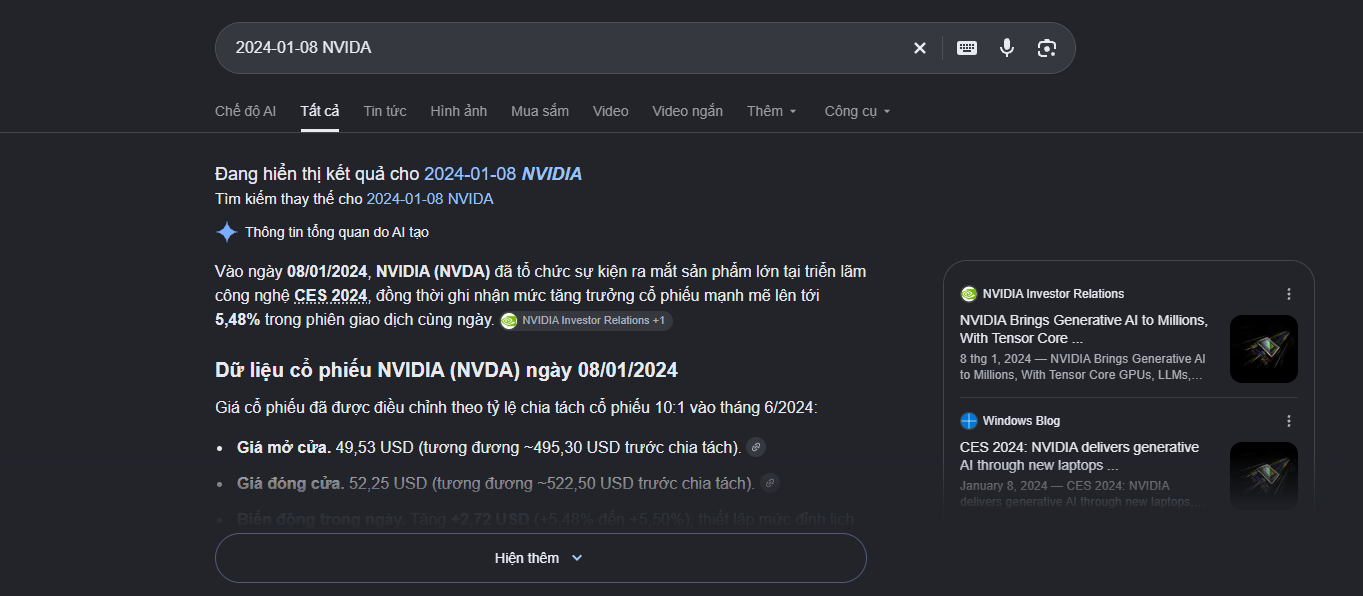

---
## Đánh gíá Residual Variance Ratio (Tỉ lệ phương sai phần dư)
- Đo lường phần trăm biến động của dữ liệu bắt nguồn từ nhiều ngẫu nhiên sau khi bóc tách trend và seasonal

### **Công thức:**

$$
\text{Ratio} = \frac{Var(Residual)}{Var(Y)}
$$

Trong đó:
- Var (Variance): phương sai
- Y: mảng dữ liệu gốc


In [85]:
resid_vr = stl_resid.var() / df_close_series.var()

print(f"Residual Variance ratio: {resid_vr * 100: 0.4f}%")

Residual Variance ratio:  0.7723%


## Đánh giá chất lượng phân rã

- Tỉ lệ Residual Variance Ratio: < 5%

- Nhận định ban đầu: Có vẻ như thuật toán STL phân rã cực kỳ hoàn hảo

### Chú ý
- Nhưng vì đây là dữ liệu giá cổ phiếu thị trường
- Trong dài hạn Trend tăng cực mạnh kéo theo phương sai cũng rất lớn
- Sẽ làm lệch Residual Variance Ratio khi mẫu số rất lớn

### -> Thử lại đánh giá lại với Detrended Data đã khử xu hướng
---

### Detrended Data (Dữ liệu đã khử xu hướng)

#### **Công thức:**

$$
Y_{detrended} = Y - Trend = Seasonal + Residual
$$

### Deseasonalized Data (Dữ liệu đã khử mùa vụ)

#### **Công thức:**

$$
Y_{deseasonalized} = Y - Seasonal = Trend + Residual
$$

In [86]:
# Detrended
detrended = df_close_series - stl_trend 

# Deseasonalized
deseasonalized = df_close_series - stl_seasional

In [87]:
# Tính lại tỉ lệ khắt khe hơn: Nhiễu so với (Mùa vụ + Nhiễu)
strict_resid_vr = stl_resid.var() / detrended.var()

print(f"Strict Residual Variance ratio: {strict_resid_vr * 100:0.4f}%")

Strict Residual Variance ratio: 68.3068%


### Đánh giá lại
- Loại bỏ ảo giác Trend, chỉ đánh giá: $$\frac{\text{Nhiễu}}{\text{Mùa vụ} + \text{Nhiễu}}$$

- Tỉ lệ Residual Variance Ratio thực tế vọt lên: ~68.3%

- Khi không còn Trend kéo, ta thấy Seasonal (Mùa vụ) rất yếu, vì hơn 2/3 biến động ngắn hạn đến từ White Noise

### -> Tiếp tục thử trên tập dữ liệu sau khi biến đổi Box-Cox và Log trên tập dữ liệu gốc

In [88]:
# Box-cox
stl_box_cox = STL(se_box_cox, period=period, seasonal=seasonal)

stl_box_cox_res = stl_box_cox.fit()

box_cox_trend, box_cox_resid = stl_box_cox_res.trend, stl_box_cox_res.resid

box_cox_detrended = se_box_cox - box_cox_trend

# Log 
stl_log = STL(se_log, period=period, seasonal=seasonal)

stl_log_res = stl_log.fit()

log_trend, log_resid = stl_log_res.trend, stl_log_res.resid

log_detrended = se_log - log_trend

# Residual Variance Rate
box_cox_resid_vr = box_cox_resid.var() / box_cox_detrended.var()

log_resid_vr = log_resid.var() / log_detrended.var()

print("---Box-cox---")
print(f"Strict Residual Variance ratio: {box_cox_resid_vr * 100:0.4f}%")

print("---Log---")
print(f"Strict Residual Variance ratio: {log_resid_vr * 100:0.4f}%")

---Box-cox---
Strict Residual Variance ratio: 68.3951%
---Log---
Strict Residual Variance ratio: 74.0190%


## Tổng kết
- Hàm Box-cox chỉ giúp tỉ lệ nhiễu trên phần detrended tăng nhẹ (68.4%) trong khi đó Log tăng vọt lên 74%

- Cho ta thấy rằng khi ổn định biên độ, hàm STL đã nhân định tính Seasonal yếu hơn thức tế

- Sự tăng lên của Nhiễu Trắng càng phản ánh điều đó

- Log cho ra giá trị tốt hơn vì hàm log ép dữ liệu mạnh tay hơn (cực kì thích hợp cho dữ liệu tài chính) trong khi đó box-cox lại theo tham số tối ưu $\lambda$

---
## Trích xuất đặc trưng thời gian

### 1. Trích xuất đặc trưng chu kì sin(2πt/T), cos(2πt/T)
- Ngày trong tuần, tháng trong năm mang tính tuần hoàn
- Nếu không biến đổi dữ liệu sẽ mang tính thứ tự, lớn bé
- Khoảng cách của Thứ 2 và Chủ Nhật sẽ bị khuếch đại (6 >> 0) khiến mô hình hiểu sai ý nghĩa.
- Việc chiếu dữ liệu lên sin, cos tạo ra sự chuyển tiếp mượt mà giữa chu kì
### *Công thức:*

$$x_{\sin} = \sin\left(\frac{2\pi t}{T}\right)$$
$$x_{\cos} = \cos\left(\frac{2\pi t}{T}\right)$$

In [89]:
# Trích xuất trên tập Detrended và Deseasonalized

# Ngày trong tuần T = 5 (dữ liệu tài chính)
T_week = 5
dow = df_close_series.index.day_of_week
index = df_close_series.index

# Check lại cho chắc có Thứ 7 hay CN không
print(df_close_series[(dow == 5) | (dow == 6)])

df_sin_week = pd.Series(np.sin(2 * np.pi * dow / T_week), index=index, name='sin_cycle')

df_cos_week = pd.Series(np.cos(2 * np.pi * dow / T_week), index=index, name='cos_cycle')

df_detrend_day_extract = pd.concat([detrended, df_sin_week, df_cos_week], axis=1) 
df_deseasonal_day_extract = pd.concat([deseasonalized, df_sin_week, df_cos_week], axis=1) 



# Tháng trong năm T = 12
T_month = 12
months = df_close_series.index.month
df_sin_month = pd.Series(np.sin(2 * np.pi * months / T_month), index=index, name='sin_cycle')

df_cos_month = pd.Series(np.cos(2 * np.pi * months / T_month), index=index, name='cos_cycle')

df_detrend_month_extract = pd.concat([detrended, df_sin_month, df_cos_month], axis=1) 
df_deseasonal_month_extract = pd.concat([deseasonalized, df_sin_month, df_cos_month], axis=1)


Series([], Name: Close, dtype: float64)


- Không có giao dịch nào ở Thứ 7 hoặc Chủ Nhật

---
### Thêm Holidays
- Các ngày lễ lớn (Holidays) thường gây ra sự bất thường (anomalies) trong dữ liệu chuỗi thời gian tài chính. Khối lượng giao dịch có thể sụt giảm ngay trước kỳ nghỉ, hoặc giá tài sản có thể biến động mạnh khi thị trường mở cửa trở lại do dồn nén thông tin


In [90]:
# Thêm ngày lễ
import holidays

us_holidays = holidays.US()

is_holiday_list = [date in us_holidays for date in df_close_series.index.date]

df_is_holiday = pd.Series(is_holiday_list, index=index, name='is_holiday')

# Detrended
df_detrend_day_extract = pd.concat([df_detrend_day_extract, df_is_holiday], axis=1)
df_detrend_month_extract = pd.concat([df_detrend_month_extract, df_is_holiday], axis=1)

# Deseasonalized
df_deseasonal_day_extract = pd.concat([df_deseasonal_day_extract, df_is_holiday], axis=1)
df_deseasonal_month_extract = pd.concat([df_deseasonal_month_extract, df_is_holiday], axis=1)

print("Trích xuất ngày trong tuần: ")
print(df_detrend_day_extract.head())

print("\nTrích xuất tháng trong năm: ")
print(df_detrend_month_extract.head())


Trích xuất ngày trong tuần: 
                   0  sin_cycle  cos_cycle  is_holiday
Date                                                  
2000-01-03 -0.062085   0.000000   1.000000       False
2000-01-04 -0.064877   0.951057   0.309017       False
2000-01-05 -0.068146   0.587785  -0.809017       False
2000-01-06 -0.074035  -0.587785  -0.809017       False
2000-01-07 -0.073133  -0.951057   0.309017       False

Trích xuất tháng trong năm: 
                   0  sin_cycle  cos_cycle  is_holiday
Date                                                  
2000-01-03 -0.062085        0.5   0.866025       False
2000-01-04 -0.064877        0.5   0.866025       False
2000-01-05 -0.068146        0.5   0.866025       False
2000-01-06 -0.074035        0.5   0.866025       False
2000-01-07 -0.073133        0.5   0.866025       False


In [91]:
print(len(df_detrend_day_extract.loc[df_detrend_day_extract['is_holiday']]))
print(len(df_detrend_month_extract.loc[df_detrend_month_extract['is_holiday']]))

# Expected: Có dữ liệu có ngày là Holiday (> 0)

58
58


In [92]:
def window_extract(original: pd.Series, window_size: int = 7):
    # Có DropNa
    rolling_mean = pd.Series(original.rolling(window=window_size).mean(), index = original.index, name=f"mean_{window_size}").dropna()
    rolling_std = pd.Series(original.rolling(window=window_size).std(), index = original.index, name=f"std_{window_size}").dropna()
    rolling_max = pd.Series(original.rolling(window=window_size).max(), index = original.index, name=f"max_{window_size}").dropna()
    rolling_min = pd.Series(original.rolling(window=window_size).min(), index = original.index, name=f"min_{window_size}").dropna()
    rolling_skew = pd.Series(original.rolling(window=window_size).skew(), index = original.index, name=f"skew_{window_size}").dropna()
    
    return pd.concat(
        [rolling_mean, rolling_std, rolling_max, rolling_min, rolling_skew],
        axis=1
        )

In [93]:
# Cho Residual
df_residual_extract_7 = window_extract(stl_resid, window_size=7)
df_residual_extract_30 = window_extract(stl_resid, window_size=30)
df_residual_extract_90 = window_extract(stl_resid, window_size=90)

# Cho detrended
df_detrend_extract_7 = window_extract(detrended, window_size=7)
df_detrend_extract_30 = window_extract(detrended, window_size=30)
df_detrend_extract_90 = window_extract(detrended, window_size=90)

# Cho deseasonalized
df_deseasonal_extract_7 = window_extract(deseasonalized, window_size=7)
df_deseasonal_extract_30 = window_extract(deseasonalized, window_size=30)
df_deseasonal_extract_90 = window_extract(deseasonalized, window_size=90)


In [94]:
print("=== Detrended - Window 7 ===")
print(df_detrend_extract_7.head(3))

print("\n=== Deseasonalized - Window 7 ===")
print(df_deseasonal_extract_7.head(3))

print("\n=== Detrended - Window 30 ===")
print(df_detrend_extract_30.head(3))

print("\n=== Deseasonalized - Window 30 ===")
print(df_deseasonal_extract_30.head(3))

=== Detrended - Window 7 ===
              mean_7     std_7     max_7     min_7    skew_7
Date                                                        
2000-01-11 -0.069695  0.004837 -0.062085 -0.074665  0.637469
2000-01-12 -0.071839  0.004185 -0.064877 -0.077096  0.662217
2000-01-13 -0.073183  0.002885 -0.068146 -0.077096  0.721786

=== Deseasonalized - Window 7 ===
              mean_7     std_7     max_7     min_7    skew_7
Date                                                        
2000-01-11  0.125132  0.006426  0.135215  0.118086  0.554537
2000-01-12  0.121745  0.006474  0.130234  0.111505 -0.084207
2000-01-13  0.120784  0.006813  0.130234  0.111505  0.376346

=== Detrended - Window 30 ===
             mean_30    std_30    max_30    min_30   skew_30
Date                                                        
2000-02-14 -0.075619  0.008953 -0.052436 -0.088453  0.352490
2000-02-15 -0.075453  0.009253 -0.052436 -0.088453  0.441564
2000-02-16 -0.075045  0.009978 -0.052436 -0.088453 

---
## Phát hiện dị thường

### 1. Phương pháp thống kê Z-score
*Công thức:*

$$
Z = \frac{X - \mu}{\sigma}
$$

### Quy tắc 3-Sigma cho quyết định anomaly
- |Z| > 3
- Khoảng tin cậy là 99.73%
- $\alpha$ là 0.0027

In [95]:
# Trên chuỗi deseaonalize
# 
z_score = (deseasonalized - deseasonalized.mean()) / deseasonalized.std()

z_score_threshold = 3

anomaly_z_score = z_score[z_score.abs() > z_score_threshold]

anomaly_z_score.head()

Date
2025-07-24    3.069593
2025-07-25    3.073067
2025-07-28    3.213258
2025-07-29    3.167697
2025-07-30    3.180303
dtype: float64

## 2. Phương pháp Isolation Forest
- Thuật toán học máy dạng cây
- Tìm cách cô lập điểm dữ liệu bằng cách thả 1 lát cách ngẫu nhiên xuống:
  - Điểm bình thường: cụm dày đặc cần rất nhiều lát cắt để cô lập
  - Điểm dị thường: cần rất ít lát cắt để cô lập chính nó

### Hướng làm
- 3 mô hình riêng: window 30.

- 1 mô hình gộp (multi-scale): ghép các đặc trưng của cả 3  (7, 30, 90).

- So sánh

- Thêm voting

In [100]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

def run_iforest(df, contamination=0.01):
    
    X = df.dropna().values
    
    model = IsolationForest(
        n_estimators=300,
        contamination=contamination,
        random_state=42
    )
    
    pred = model.fit_predict(X)          
    score = model.decision_function(X)   
    return pd.DataFrame({'score': score, 'is_anomaly': pred == -1}, index=df.index)

In [101]:
df_iforest_size_30 = run_iforest(df_deseasonal_extract_30)

feat_all = pd.concat([df_deseasonal_extract_7, df_deseasonal_extract_30, df_deseasonal_extract_90], axis=1).dropna()

df_iforest_all =  run_iforest(feat_all)

In [102]:
print(len(df_iforest_size_30[df_iforest_size_30['is_anomaly']]))
print(len(df_iforest_all[df_iforest_all['is_anomaly']]))

67
67


In [103]:
df_compare = pd.merge(
    df_iforest_size_30[['is_anomaly']],
    df_iforest_all[['is_anomaly']],
    left_index=True,
    right_index=True,
    suffixes=('_size_7', '_all')
)

df_compare['is_equal'] = (
    df_compare['is_anomaly_size_7'] ==
    df_compare['is_anomaly_all']
)

print("Số dòng giống nhau:", df_compare['is_equal'].sum())
print("Số dòng khác nhau:", (~df_compare['is_equal']).sum())
print("Tỷ lệ giống nhau:", df_compare['is_equal'].mean())

Số dòng giống nhau: 6597
Số dòng khác nhau: 70
Tỷ lệ giống nhau: 0.9895005249737513


## 3. Phương pháp dùng Autoencoder 1D
- Là 1 mạng nén và mạng giải nén dữ liệu
- Học pattern, nén và giải nén tốt thì là chuỗi bình thường và ngược lại
- Dùng trên cửa sổ trượt window size = 30

In [119]:
import torch
import torch.nn as nn

if torch.cuda.is_available():
    device = 'cuda'
elif torch.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

class TimeSeriesAutoEncoder(nn.Module):
    encoder: nn.Module
    decoder:nn.Module

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=32, kernel_size=7, stride=2, padding=3),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Conv1d(in_channels=32, out_channels=16, kernel_size=7, stride=2, padding=3),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(in_channels=16, out_channels=32, kernel_size=7, stride=2, padding=3, output_padding=0),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.ConvTranspose1d(in_channels=32, out_channels=1, kernel_size=7, stride=2, padding=3, output_padding=1)
        )

    def forward(self, X):
        X = self.encoder(X)
        X = self.decoder(X)
        return X


In [130]:
from numpy.lib.stride_tricks import sliding_window_view


def train(model:nn.Module, X, y, criterion, optimizer, epochs):
    model.train()
    losses = []
    
    for epoch in range(epochs):
        
        optimizer.zero_grad()

        y_pred = model(X)

        loss = criterion(y_pred, y)
        losses.append(loss.item())
        loss.backward()

        optimizer.step()

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1}/{epochs}: Loss = {loss: .4f}")

    return losses

def init_model_and_train_autoencoder(df:pd.DataFrame, epochs=50):
    X = df.to_numpy().reshape(-1, 1)

    scaler = StandardScaler()
    X = scaler.fit_transform(X).flatten()

    # 2. Cắt cửa sổ SAU KHI đã chuẩn hóa
    X_windowed = sliding_window_view(X, window_shape=30)
    # Shape lúc này: (6754, 3)

    # 3. Chèn thêm chiều Channel (Dimension = 1) vào giữa cho PyTorch
    X_final = np.expand_dims(X_windowed, axis=1)
    X_final = torch.tensor(X_final, dtype=torch.float32).to(device)

    model = TimeSeriesAutoEncoder().to(device)

    mae = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    losses = train(model, X_final, X_final, mae, optimizer, epochs=epochs)

    return model, losses, scaler, X_final,

In [131]:
init_model_and_train_autoencoder(deseasonalized, epochs=100)

Epoch 1/100: Loss =  0.4179
Epoch 10/100: Loss =  0.2812
Epoch 20/100: Loss =  0.1585
Epoch 30/100: Loss =  0.1172
Epoch 40/100: Loss =  0.1024
Epoch 50/100: Loss =  0.0913
Epoch 60/100: Loss =  0.0797
Epoch 70/100: Loss =  0.0694
Epoch 80/100: Loss =  0.0638
Epoch 90/100: Loss =  0.0600
Epoch 100/100: Loss =  0.0574


(TimeSeriesAutoEncoder(
   (encoder): Sequential(
     (0): Conv1d(1, 32, kernel_size=(7,), stride=(2,), padding=(3,))
     (1): ReLU()
     (2): Dropout(p=0.2, inplace=False)
     (3): Conv1d(32, 16, kernel_size=(7,), stride=(2,), padding=(3,))
     (4): ReLU()
   )
   (decoder): Sequential(
     (0): ConvTranspose1d(16, 32, kernel_size=(7,), stride=(2,), padding=(3,))
     (1): ReLU()
     (2): Dropout(p=0.2, inplace=False)
     (3): ConvTranspose1d(32, 1, kernel_size=(7,), stride=(2,), padding=(3,), output_padding=(1,))
   )
 ),
 [0.4179498255252838,
  0.40491434931755066,
  0.394228458404541,
  0.38317352533340454,
  0.37146836519241333,
  0.35770663619041443,
  0.34261828660964966,
  0.3244997560977936,
  0.30428940057754517,
  0.28121137619018555,
  0.2547945976257324,
  0.2270837426185608,
  0.19463853538036346,
  0.16427338123321533,
  0.14058460295200348,
  0.13006433844566345,
  0.13232247531414032,
  0.14398883283138275,
  0.1534060388803482,
  0.15845127403736115,
  0.15569

cpu
